# Đề án 03 — Đo lường rủi ro thị trường: VaR, ES và kiểm định ngược
**Danh mục Việt–Mỹ (VN-Index & S&P 500 quy đổi VND), theo khoảng thời gian trong hai file clean**

> Câu hỏi trung tâm: *Phân bổ một phần danh mục từ VN-Index sang S&P 500 có giúp nhà đầu tư Việt Nam giảm rủi ro tổn thất lớn không, và lợi ích đó thay đổi thế nào trong các giai đoạn căng thẳng?*

Notebook này **gọi hàm trong `src/market_risk`**; mọi tham số ở `config.yaml`, seed = 2026. Bước rolling dùng cache (`data/processed/rolling_cache`) nên chạy lại nhanh.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, Markdown, display
from market_risk.config import load_config, read_table, setup_logging
from market_risk import data_pipeline, inflation, portfolio, descriptive, rolling, overall, diversification, fx_inflation, spillover, stress, application, plots, reporting
from market_risk.backtest import runner as backtest
cfg = load_config(); log = setup_logging('notebook')
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
FIG = ROOT / 'outputs' / 'figures'
def fig(name): display(Image(filename=str(FIG / f'{name}.png'), width=900))

## 1. Dữ liệu (Phase 1)
Hai file trong `data/clean/`: giá đóng cửa ngày VN-Index (HOSE), S&P 500 và tỷ giá USD/VND từ Investing.com; CPI Việt Nam theo tháng từ IMF IFS (2010 = 100), chỉ dùng để phân loại bối cảnh lạm phát. Giá S&P 500 được đối chiếu với FRED SP500 (T0b).

In [2]:
prices = data_pipeline.run(cfg)
monthly = inflation.run(prices.index, cfg)
ret = portfolio.run(prices, cfg)
display(read_table('T0_data_quality'))

10:07:46 | INFO    | market_risk.data_pipeline | Đang đọc dữ liệu clean từ C:\Users\X1\AppData\Local\Packages\Claude_pzs8sxrjxfjjc\LocalCache\Roaming\Claude\scratch-workspaces\a61389fd-53fd-443f-8f94-48c006a13016\ca9ca959-b22c-43c3-961f-c192fed66f96\scratch-2026-09-30-f45ee8\v3\DeAn03_VaR_ES_Backtesting\data\clean\cleaned_daily_data.csv...


10:07:46 | INFO    | market_risk | Đã lưu bảng T0_fx_cleaning_log.csv (3 dòng)


10:07:46 | INFO    | market_risk.data_pipeline | USDVND: lọc 3 điểm lỗi báo giá (chi tiết T0_fx_cleaning_log)


10:07:46 | INFO    | market_risk | Đã lưu bảng T0b_fred_sp500_check.csv (1 dòng)


10:07:46 | INFO    | market_risk.data_pipeline | S&P 500 so với FRED SP500: 2036 phiên trùng, lệch tối đa 0.0024%


...

10:07:46 | INFO    | market_risk | Đã lưu bảng T0_top_moves.csv (30 dòng)


10:07:46 | INFO    | market_risk.data_pipeline | Đã dùng hai file clean: 4610 ngày giá; 4609 ngày ghép lệch pha


10:07:46 | INFO    | market_risk.inflation | Đang đọc CPI clean từ C:\Users\X1\AppData\Local\Packages\Claude_pzs8sxrjxfjjc\LocalCache\Roaming\Claude\scratch-workspaces\a61389fd-53fd-443f-8f94-48c006a13016\ca9ca959-b22c-43c3-961f-c192fed66f96\scratch-2026-09-30-f45ee8\v3\DeAn03_VaR_ES_Backtesting\data\clean\cleaned_cpi_inflation.csv...


10:07:46 | INFO    | market_risk.inflation | Lạm phát YoY từ 2006-01-01 đến 2026-07-01; tỷ lệ tháng 'Cao' = 51%


,series,N_raw,N_clean,n_flagged_errors,start,end,n_missing,n_dup_dates,dropped_by_merge,pct_dropped_by_merge
0,VN,4610,4610,0.0,2006-02-07,2025-02-28,0.0,0.0,0.0,0.0
1,SP_USD,4610,4610,0.0,2006-02-07,2025-02-28,0.0,0.0,0.0,0.0
2,USDVND,4610,4610,3.0,2006-02-07,2025-02-28,0.0,0.0,0.0,0.0
3,MERGED (inner),4610,4610,NaN,2006-02-07,2025-02-28,NaN,NaN,NaN,NaN


10:07:48 | INFO    | market_risk.plots | Đã lưu hình F1_normalized_prices


10:07:49 | INFO    | market_risk.plots | Đã lưu hình F6_inflation_regime


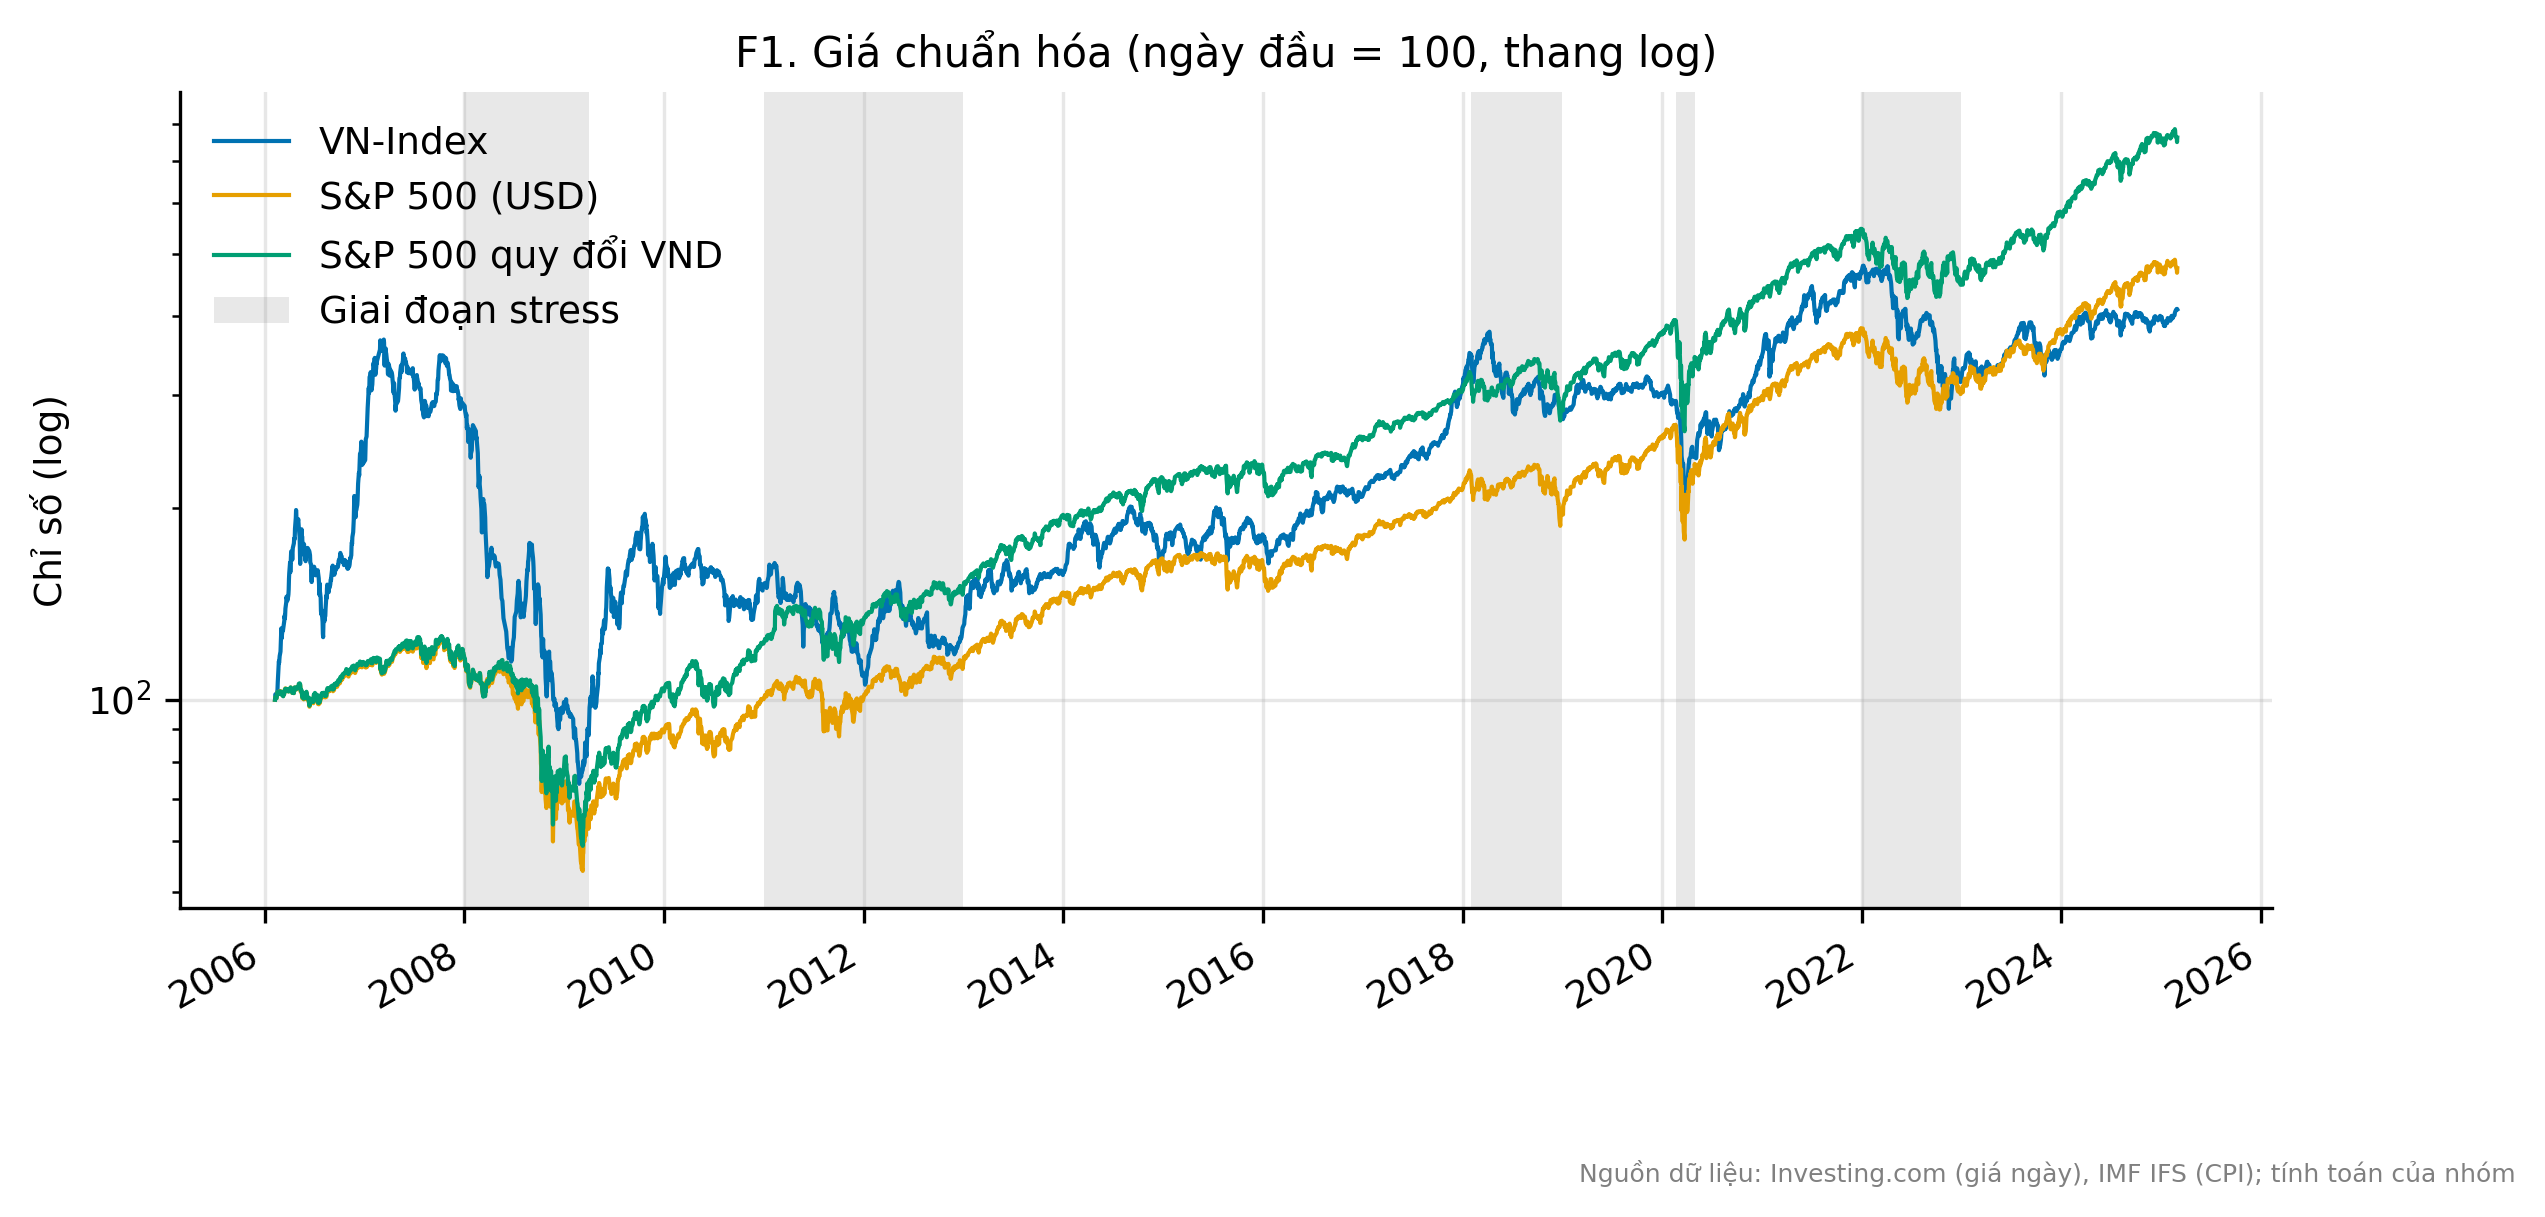

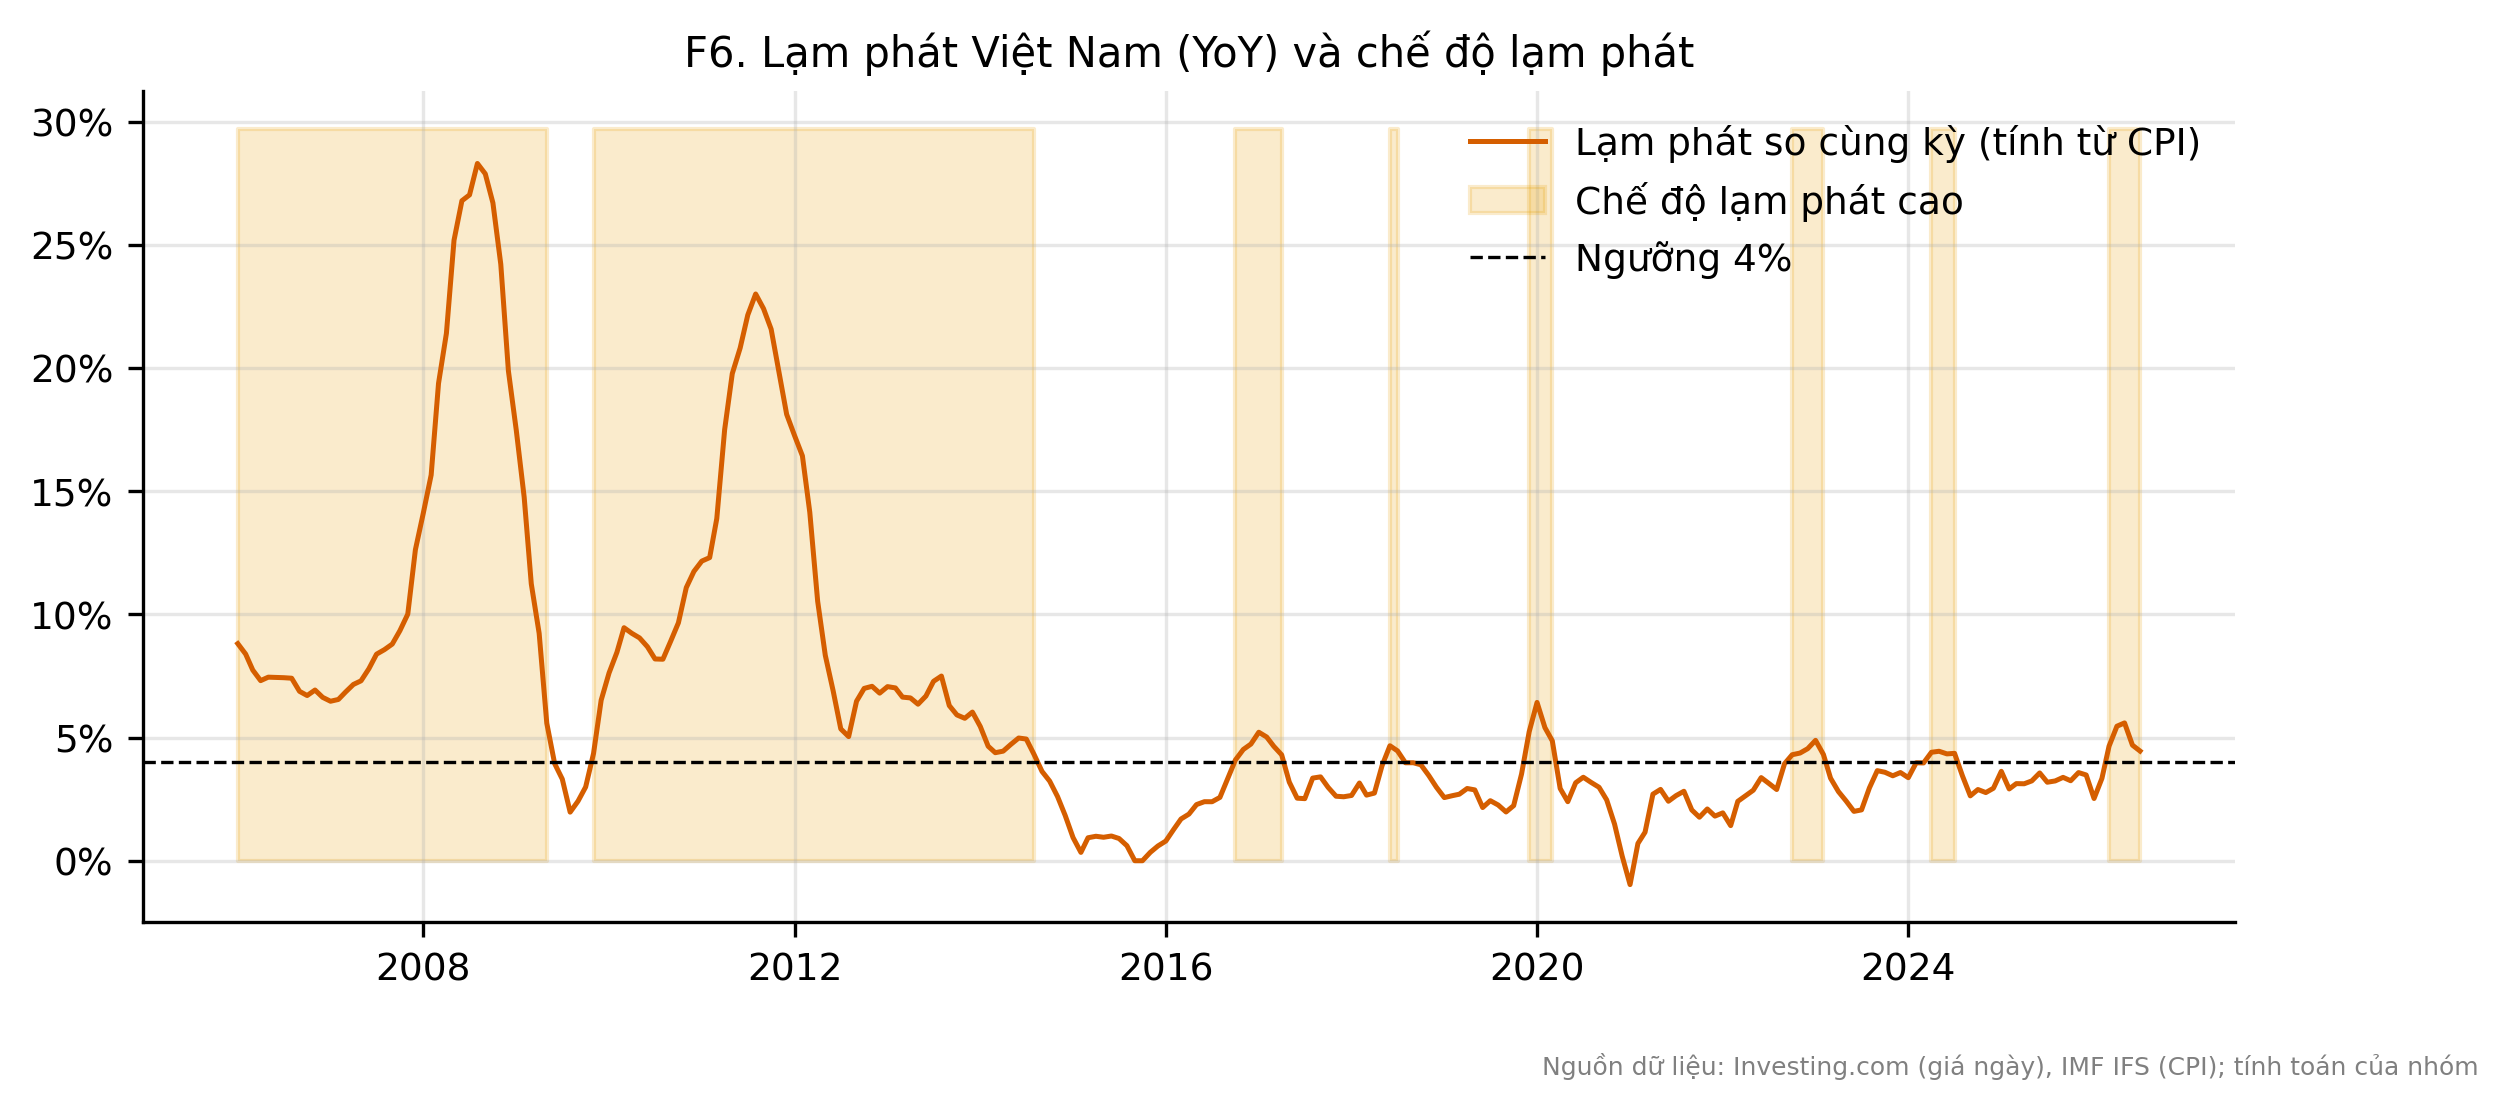

In [3]:
# Xem trước giá chuẩn hóa và lạm phát (các hình còn lại vẽ ở cuối)
plots.f1_prices(prices, cfg); plots.f6_inflation(cfg)
fig('F1_normalized_prices'); fig('F6_inflation_regime')

## 2. Thống kê mô tả và kiểm định giả định (Phase 2)
Jarque–Bera/Anderson–Darling (chuẩn — giả định của Normal, MC_Normal), ADF/KPSS (tính dừng), ARCH-LM và Ljung–Box trên r² (biến động theo cụm — căn cứ dùng GARCH).

In [4]:
print(descriptive.run(cfg=cfg))
display(read_table('T1_descriptive').query("period=='Toàn kỳ'"))
read_table('T2_assumption_tests')[['label','test','statistic','p_value','conclusion']]

10:07:50 | INFO    | market_risk | Đã lưu bảng T1_descriptive.csv (42 dòng)


10:07:51 | INFO    | market_risk | Đã lưu bảng T2_assumption_tests.csv (40 dòng)


- Jarque–Bera bác bỏ phân phối chuẩn ở 5/5 chuỗi → giả định chuẩn của Normal và MC_Normal không được dữ liệu ủng hộ; HS (không giả định phân phối) là mô hình đối chứng.
- ARCH-LM(10) có ý nghĩa ở 4/5 chuỗi và Ljung–Box trên r² ở 4/5 chuỗi → biến động theo cụm, là căn cứ dùng GARCH(1,1).
- ADF bác bỏ nghiệm đơn vị ở 5/5 chuỗi lợi suất (KPSS không bác bỏ tính dừng ở 5/5) → mô hình hóa trên lợi suất là phù hợp.


,period,series,label,N,mean,std,mean_ann,std_ann,min,max,skew,exkurt,q01,q025,q05
0,Toàn kỳ,VN,VN-Index,4609,0.000306,0.014464,0.077049,0.229608,-0.080623,0.086870,-0.292896,2.83334,-0.043874,-0.034438,-0.025369
1,Toàn kỳ,SP_USD,S&P 500 (USD),4609,0.000338,0.012532,0.085139,0.198938,-0.127657,0.109644,-0.502208,12.29400,-0.036272,-0.026262,-0.018786
2,Toàn kỳ,SP_VND,S&P 500 (VND),4609,0.000440,0.012682,0.110951,0.201314,-0.126925,0.110247,-0.419259,11.94520,-0.036663,-0.026595,-0.018944
3,Toàn kỳ,USDVND,USD/VND,4609,0.000102,0.001975,0.025812,0.031359,-0.015312,0.060745,8.364330,220.46600,-0.004754,-0.003208,-0.002113
4,Toàn kỳ,VN50_SP50,DM 50/50,4609,0.000418,0.009784,0.105240,0.155309,-0.075869,0.055964,-0.650770,5.35336,-0.028908,-0.020831,-0.015410
5,Toàn kỳ,VN100,DM 100% VN,4609,0.000306,0.014464,0.077049,0.229608,-0.080623,0.086870,-0.292896,2.83334,-0.043874,-0.034438,-0.025369
6,Toàn kỳ,SP100,DM 100% S&P,4609,0.000440,0.012682,0.110951,0.201314,-0.126925,0.110247,-0.419259,11.94520,-0.036663,-0.026595,-0.018944


,label,test,statistic,p_value,conclusion
0,VN-Index,Jarque–Bera,1.607580e+03,0.000000e+00,Bác bỏ phân phối chuẩn → Normal/MC_Normal dễ đ...
1,VN-Index,Anderson–Darling,5.908280e+01,0.000000e+00,Bác bỏ chuẩn
2,VN-Index,ADF,-1.671520e+01,1.423530e-29,Bác bỏ nghiệm đơn vị → dừng
3,VN-Index,KPSS,5.633050e-02,1.000000e-01,Không bác bỏ tính dừng
4,VN-Index,ARCH-LM(5),6.393140e+02,6.459530e-136,Có hiệu ứng ARCH (biến động theo cụm) → cần GARCH
5,VN-Index,ARCH-LM(10),7.660620e+02,4.064120e-158,Có hiệu ứng ARCH (biến động theo cụm) → cần GARCH
6,VN-Index,Ljung–Box Q(10) r,1.925930e+02,5.642130e-36,Có tự tương quan trong lợi suất
7,VN-Index,Ljung–Box Q(10) r²,2.084570e+03,0.000000e+00,Có tự tương quan trong r² (cụm biến động)
8,S&P 500 (USD),Jarque–Bera,2.921920e+04,0.000000e+00,Bác bỏ phân phối chuẩn → Normal/MC_Normal dễ đ...
9,S&P 500 (USD),Anderson–Darling,inf,0.000000e+00,Bác bỏ chuẩn


## 3. MT1 — Ước lượng VaR/ES bằng bốn phương pháp, rolling 252 phiên (Phase 3–4)
Mô phỏng lịch sử (HS), phương pháp tham số chuẩn (Normal), Monte Carlo chuẩn (MC_Normal) và GARCH(1,1)-Normal (GARCH_N).

In [5]:
fc = rolling.run(cfg)
print(overall.run(cfg))
t4 = read_table('T4_var_es_overall')
t4[t4['sample']=='common'].pivot(index='model', columns='portfolio', values='ES_975').mul(100).round(2)

10:07:52 | INFO    | market_risk.rolling | Rolling: 70 tổ hợp, n_jobs = -1


10:08:17 | INFO    | market_risk | Đã lưu bảng T4b_rolling_runtime.csv (70 dòng)


10:08:18 | INFO    | market_risk.rolling | Rolling xong: 274156 dòng; tỷ lệ NaN (main) = 0.000%


10:08:18 | INFO    | market_risk | Đã lưu bảng T3_garch_params.csv (5 dòng)


10:08:19 | INFO    | market_risk | Đã lưu bảng T4_var_es_overall.csv (24 dòng)


10:08:19 | INFO    | market_risk | Đã lưu bảng T4a_var_es_static.csv (12 dòng)


- ES 97,5% trung bình (mẫu chung) của danh mục 50/50 thấp hơn 100% VN ở 4/4 phương pháp; mức giảm trung vị 32.7% (từ 30.6% đến 34.1%) — T4_var_es_overall.
- ES trung bình 100% VN: 3.16%/ngày; 50/50: 2.13%; 100% S&P (VND): 2.70% (trung vị qua các mô hình).
- Chênh lệch giữa mô hình cao nhất và thấp nhất: VN 0.75 điểm %, 50/50 0.63, S&P 0.87 → lựa chọn mô hình quan trọng không kém lựa chọn tỷ trọng.


portfolio,SP100,VN100,VN50_SP50
model,,,
GARCH_N,2.42,2.97,1.96
HS,3.28,3.73,2.59
MC_Normal,2.70,3.17,2.13
Normal,2.69,3.16,2.12


In [6]:
display(read_table('T3_garch_params')[['series','model','mu','omega','alpha','beta','persistence','half_life_days','BIC']])

,series,model,mu,omega,alpha,beta,persistence,half_life_days,BIC
0,VN100,GARCH_N,0.000456,0.000004,0.136790,0.849168,0.985958,49.0147,-27437.2
1,VN50_SP50,GARCH_N,0.000705,0.000002,0.133442,0.849981,0.983423,41.4652,-31066.4
2,SP100,GARCH_N,0.000853,0.000003,0.149326,0.833119,0.982445,39.1367,-29718.8
3,SP_USD,GARCH_N,0.000770,0.000003,0.141754,0.839935,0.981688,37.5049,-29837.2
4,USDVND,GARCH_N,0.000227,0.000001,0.709761,0.290239,1.000000,inf,-45132.1


## 4. MT4 — Kiểm định ngược VaR (Phase 5)
Chỉ sử dụng Kupiec (tần suất vi phạm) và Christoffersen (độc lập, bao phủ có điều kiện). ES được báo cáo như thước đo rủi ro, không có kiểm định ES.

In [7]:
bt = backtest.run(cfg=cfg)
t5 = bt['T5']
t5[(t5.set=='main')&(t5.level==0.99)][['portfolio','model','T','x','expected','rate','p_uc','p_ind','p_cc','conclusion']]

10:08:20 | INFO    | market_risk | Đã lưu bảng T5_backtest_var.csv (210 dòng)


10:08:20 | INFO    | market_risk.backtest.runner | Kupiec/Christoffersen xong: 210 dòng


,portfolio,model,T,x,expected,rate,p_uc,p_ind,p_cc,conclusion
5,SP100,GARCH_N,4357,123,43.57,0.028230,4.368765e-23,0.776107,5.255406e-22,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
23,SP100,HS,4357,84,43.57,0.019279,4.781529e-08,0.006408,8.212813e-09,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
35,SP100,MC_Normal,4357,133,43.57,0.030526,6.796019e-28,0.002984,1.144354e-28,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
47,SP100,Normal,4357,133,43.57,0.030526,6.796019e-28,0.002984,1.144354e-28,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
71,VN100,GARCH_N,4357,99,43.57,0.022722,4.610814e-13,0.625737,3.781193e-12,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
89,VN100,HS,4357,54,43.57,0.012394,1.257919e-01,0.000042,7.086620e-05,Không đạt: Christoffersen bác bỏ bao phủ có đi...
101,VN100,MC_Normal,4357,90,43.57,0.020656,6.317127e-10,0.000014,3.883903e-13,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
113,VN100,Normal,4357,90,43.57,0.020656,6.317127e-10,0.000014,3.883903e-13,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
125,VN50_SP50,GARCH_N,4357,106,43.57,0.024329,9.503224e-16,0.018760,6.135265e-16,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...
143,VN50_SP50,HS,4357,62,43.57,0.014230,8.326888e-03,0.000220,3.335709e-05,Không đạt: Kupiec bác bỏ tần suất vi phạm; Chr...


## 5. MT2 — Lợi ích đa dạng hóa theo thời gian (Phase 6)
*Phân tích mô tả — 'đi kèm với', không phải 'gây ra'.*

In [8]:
print(diversification.run(cfg))
read_table('T8_diversification_by_corr').query("corr_measure=='corr_252'")

10:09:26 | INFO    | market_risk | Đã lưu bảng T8_diversification_by_corr.csv (160 dòng)


10:09:26 | INFO    | market_risk | Đã lưu bảng T8a_dr_regression_nw.csv (20 dòng)


10:09:26 | INFO    | market_risk | Đã lưu bảng T8b_tail_correlation.csv (10 dòng)


10:09:26 | INFO    | market_risk | Đã lưu bảng T8c_dcc_params.csv (2 dòng)


10:09:26 | INFO    | market_risk | Đã lưu bảng T8d_forbes_rigobon.csv (10 dòng)


10:09:26 | WARNING | market_risk.diversification | DR âm ở 0.49% số ngày — kiểm tra (ES ước lượng không nhất thiết dưới cộng tính trên mẫu hữu hạn)


- Lợi ích đa dạng hóa tương đối (DR) trung bình 29.6% khi tương quan 252 phiên ở tam phân vị thấp, so với 24.3% ở tam phân vị cao (chênh -5.3 điểm %, p block bootstrap = 0.015) — T8_diversification_by_corr.
- Hồi quy mô tả DR theo ρ (Newey–West): b = -0.115 (p = 0.133); hệ số âm nghĩa là lợi ích đa dạng hóa **đi kèm với** mức thấp hơn khi tương quan cao hơn (không hàm ý nhân quả).
- Tương quan khi cả hai thị trường cùng giảm mạnh (10% đuôi) = 0.13 so với 0.05 nếu lợi suất là Normal cùng ρ — T8b_tail_correlation.
- Với dữ liệu lệch pha, tương quan trong các giai đoạn stress dao động 0.12–0.37 (yên ổn 0.19); sau hiệu chỉnh Forbes–Rigobon còn 0.06–0.26 — T8d_forbes_rigobon.


,corr_measure,metric,tercile,N,corr_mean,mean,median,welch_t,p_welch,p_mannwhitney,p_block_bootstrap,sig,model
0,corr_252,DB,Thấp,1452,-0.083725,0.015197,0.016237,NaN,NaN,NaN,NaN,NaN,HS
1,corr_252,DB,Trung bình,1452,0.036273,0.011436,0.012760,NaN,NaN,NaN,NaN,NaN,HS
2,corr_252,DB,Cao,1453,0.186264,0.007537,0.009491,NaN,NaN,NaN,NaN,NaN,HS
3,corr_252,DB,Cao − Thấp,2905,NaN,-0.007661,NaN,-33.0085,1.396620e-201,1.235510e-207,0.0000,***,HS
4,corr_252,DR,Thấp,1452,-0.083725,0.309520,0.292064,NaN,NaN,NaN,NaN,NaN,HS
5,corr_252,DR,Trung bình,1452,0.036273,0.293576,0.298982,NaN,NaN,NaN,NaN,NaN,HS
6,corr_252,DR,Cao,1453,0.186264,0.206312,0.219101,NaN,NaN,NaN,NaN,NaN,HS
7,corr_252,DR,Cao − Thấp,2905,NaN,-0.103208,NaN,-49.5840,0.000000e+00,0.000000e+00,0.0000,***,HS
40,corr_252,DB,Thấp,1452,-0.083725,0.013937,0.012024,NaN,NaN,NaN,NaN,NaN,Normal
41,corr_252,DB,Trung bình,1452,0.036273,0.010068,0.010165,NaN,NaN,NaN,NaN,NaN,Normal


## 6. MT3 — Tỷ giá và bối cảnh lạm phát (Phase 7) + VAR/Granger (Bài 9)

In [9]:
print(fx_inflation.run(cfg))
print(spillover.run(cfg))
display(read_table('T9_fx_effect').query("period=='Toàn kỳ'"))
display(read_table('T10_inflation_regimes').query("split=='ngưỡng 4%'"))

10:09:37 | INFO    | market_risk | Đã lưu bảng T9_fx_effect.csv (60 dòng)


10:09:37 | INFO    | market_risk | Đã lưu bảng T9b_component_es.csv (36 dòng)


10:09:37 | INFO    | market_risk | Đã lưu bảng T10_inflation_regimes.csv (36 dòng)


10:09:37 | INFO    | market_risk | Đã lưu bảng T10b_real_returns.csv (3 dòng)


10:09:37 | INFO    | market_risk | Đã lưu bảng T9c_clean_sample_robustness.csv (2 dòng)


...

10:09:38 | INFO    | market_risk | Đã lưu bảng T16_var_granger.csv (6 dòng)


10:09:38 | INFO    | market_risk | Đã lưu bảng T16_var_fevd.csv (3 dòng)


- VAR(1) chọn theo BIC, mô hình ổn định = True. S&P 500 → VN-Index: F = 278.4, p = 6.7e-62; USD/VND → VN-Index: p = 0.873 — T16_var_granger.
- Sau 10 ngày, cú sốc S&P giải thích 6.7% và tỷ giá 0.1% phương sai sai số dự báo của VN-Index — T16_var_fevd.


,period,portfolio,corr_SPUSD_FX,model,ES_VND,ES_USD,dES_FX,dES_FX_pct,conclusion
0,Toàn kỳ,100% S&P,-0.00259,HS tĩnh (toàn giai đoạn),0.040348,0.040465,-0.000117,-0.288472,Tỷ giá đóng vai trò ĐỆM (ES bằng VND thấp hơn)
1,Toàn kỳ,100% S&P,-0.00259,HS (rolling),0.032836,0.032680,0.000156,0.477284,Tỷ giá LÀM TĂNG rủi ro đuôi khi quy đổi VND
2,Toàn kỳ,100% S&P,-0.00259,Normal (rolling),0.026913,0.026627,0.000286,1.072940,Tỷ giá LÀM TĂNG rủi ro đuôi khi quy đổi VND
3,Toàn kỳ,100% S&P,-0.00259,MC_Normal (rolling),0.027004,0.026717,0.000287,1.074200,Tỷ giá LÀM TĂNG rủi ro đuôi khi quy đổi VND
4,Toàn kỳ,100% S&P,-0.00259,GARCH_N (rolling),0.024183,0.023991,0.000192,0.800384,Tỷ giá LÀM TĂNG rủi ro đuôi khi quy đổi VND
5,Toàn kỳ,50/50,-0.00259,HS tĩnh (toàn giai đoạn),0.030573,0.030807,-0.000234,-0.758680,Tỷ giá đóng vai trò ĐỆM (ES bằng VND thấp hơn)
6,Toàn kỳ,50/50,-0.00259,HS (rolling),0.025873,0.026041,-0.000168,-0.643506,Tỷ giá đóng vai trò ĐỆM (ES bằng VND thấp hơn)
7,Toàn kỳ,50/50,-0.00259,Normal (rolling),0.021232,0.021243,-0.000011,-0.053394,Tỷ giá đóng vai trò ĐỆM (ES bằng VND thấp hơn)
8,Toàn kỳ,50/50,-0.00259,MC_Normal (rolling),0.021304,0.021316,-0.000011,-0.052562,Tỷ giá đóng vai trò ĐỆM (ES bằng VND thấp hơn)
9,Toàn kỳ,50/50,-0.00259,GARCH_N (rolling),0.019585,0.019657,-0.000071,-0.362874,Tỷ giá đóng vai trò ĐỆM (ES bằng VND thấp hơn)


,split,metric,mean_Thap,mean_TrungBinh,mean_Cao,diff_Cao_Thap,N_Cao,N_Thap,p_block_bootstrap,sig
0,ngưỡng 4%,ES_VN,0.025465,NaN,0.034110,0.008645,2146,2211,0.0000,***
1,ngưỡng 4%,ES_5050,0.017235,NaN,0.022007,0.004772,2146,2211,0.0090,***
2,ngưỡng 4%,ES_SP,0.021225,NaN,0.027231,0.006006,2146,2211,0.0405,**
3,ngưỡng 4%,vol21_VN100,0.167593,NaN,0.220318,0.052725,2146,2211,0.0015,***
4,ngưỡng 4%,vol21_VN50_SP50,0.119727,NaN,0.147046,0.027319,2146,2211,0.0375,**
5,ngưỡng 4%,vol21_SP100,0.151893,NaN,0.189110,0.037217,2146,2211,0.0970,*
6,ngưỡng 4%,corr_63,0.092066,NaN,-0.009436,-0.101503,2146,2211,0.0015,***
7,ngưỡng 4%,DB,0.008230,NaN,0.012103,0.003873,2146,2211,0.0015,***
8,ngưỡng 4%,DR,0.257274,NaN,0.266508,0.009234,2146,2211,0.5300,NaN


## 7. MT5 — Stress test 2008, 2018, 2020, 2022 (Phase 8)

In [10]:
print(stress.run(cfg))
display(read_table('T11b_stress_worst_models')[['period','portfolio','role','model','UR_VaR99','UR_ES']])
display(read_table('T12_stress_hypothetical'))

10:09:39 | INFO    | market_risk | Đã lưu bảng T11_stress_historical.csv (60 dòng)


10:09:39 | INFO    | market_risk | Đã lưu bảng T11b_stress_worst_models.csv (30 dòng)


10:09:39 | INFO    | market_risk | Đã lưu bảng T12_stress_hypothetical.csv (25 dòng)


10:09:39 | INFO    | market_risk | Đã lưu bảng T13_robustness.csv (70 dòng)


- Trung bình qua 4 giai đoạn lõi và 3 danh mục, tỷ lệ vi phạm VaR99 gấp 9.0 lần kỳ vọng với Normal (cao nhất) và 5.5 lần với GARCH_N (thấp nhất) — T11_stress_historical.
- Mô hình xuất hiện nhiều nhất ở vị trí 'đánh giá thiếu rủi ro nhất': Normal (8), GARCH_N (4), MC_Normal (2) — T11b_stress_worst_models.
- Số phiên trung vị từ vi phạm VaR99 đầu tiên trong giai đoạn đến khi VaR99 tăng gấp đôi: mô hình có điều kiện 10 phiên, mô hình phi điều kiện 16 phiên (cột reaction_lag_days; bỏ qua trường hợp VaR không tăng gấp đôi trong 60 phiên).


,period,portfolio,role,model,UR_VaR99,UR_ES
0,COVID_2020,SP100,sát kỳ vọng nhất,GARCH_N,6.25000,1.225160
1,COVID_2020,SP100,đánh giá thiếu nhất,Normal,22.91670,2.116980
2,COVID_2020,VN100,sát kỳ vọng nhất,GARCH_N,10.41670,1.581700
3,COVID_2020,VN100,đánh giá thiếu nhất,Normal,18.75000,1.767140
4,COVID_2020,VN50_SP50,sát kỳ vọng nhất,HS,10.41670,1.371790
5,COVID_2020,VN50_SP50,đánh giá thiếu nhất,GARCH_N,18.75000,2.199380
6,GFC_2008,SP100,sát kỳ vọng nhất,GARCH_N,3.74150,1.064150
7,GFC_2008,SP100,đánh giá thiếu nhất,Normal,6.80272,1.236460
8,GFC_2008,VN100,sát kỳ vọng nhất,GARCH_N,1.02041,0.995101
9,GFC_2008,VN100,đánh giá thiếu nhất,HS,2.04082,1.023680


,scenario,portfolio,pnl_pct,pnl_vnd,VaR99_base,VaR99_stressed,ES975_base,ES975_stressed,dES_pct
0,VND mất giá 5% (USD/VND +5%),W100_0,0.000000,0.0,NaN,NaN,NaN,NaN,NaN
1,VN −7% (sàn HOSE) & S&P −10%,W100_0,-0.070000,-70000000.0,NaN,NaN,NaN,NaN,NaN
2,"VN −7%, S&P −10% & VND mất giá 5%",W100_0,-0.070000,-70000000.0,NaN,NaN,NaN,NaN,NaN
3,VND mất giá 5% (USD/VND +5%),W75_25,0.012500,12500000.0,NaN,NaN,NaN,NaN,NaN
4,VN −7% (sàn HOSE) & S&P −10%,W75_25,-0.077500,-77500000.0,NaN,NaN,NaN,NaN,NaN
5,"VN −7%, S&P −10% & VND mất giá 5%",W75_25,-0.066250,-66250000.0,NaN,NaN,NaN,NaN,NaN
6,VND mất giá 5% (USD/VND +5%),W50_50,0.025000,25000000.0,NaN,NaN,NaN,NaN,NaN
7,VN −7% (sàn HOSE) & S&P −10%,W50_50,-0.085000,-85000000.0,NaN,NaN,NaN,NaN,NaN
8,"VN −7%, S&P −10% & VND mất giá 5%",W50_50,-0.062500,-62500000.0,NaN,NaN,NaN,NaN,NaN
9,VND mất giá 5% (USD/VND +5%),W25_75,0.037500,37500000.0,NaN,NaN,NaN,NaN,NaN


## 8. Application — phân bổ theo giới hạn ES và khuyến nghị mô hình (Phase 9)

In [11]:
text = application.run(cfg)
display(Markdown(text))
read_table('T15_model_recommendation')

10:09:42 | INFO    | market_risk | Đã lưu bảng T5b_pass_table.csv (12 dòng)


10:09:42 | INFO    | market_risk | Đã lưu bảng T14_allocation_es_limits.csv (140 dòng)


10:09:42 | INFO    | market_risk | Đã lưu bảng T14b_allocation_consistency.csv (60 dòng)


10:09:42 | INFO    | market_risk | Đã lưu bảng T15_model_recommendation.csv (4 dòng)


# Application — Phân bổ theo giới hạn ES (bản nháp tự sinh)

> **CẢNH BÁO:** Không có phương pháp nào đồng thời được cả Kupiec và Christoffersen ủng hộ ở VaR 99%. Mô phỏng lịch sử (HS) chỉ được dùng để mô tả kết quả thăm dò, không làm căn cứ kết luận.
> Số liệu: `outputs/tables/T14_allocation_es_limits.csv`, `T14b_allocation_consistency.csv`, `T15_model_recommendation.csv`.

**(a) Kết quả thăm dò — chưa đủ điều kiện kết luận.**
Theo Mô phỏng lịch sử (HS) (ES 97,5% trung bình, %/ngày): Tỷ trọng có ES thấp nhất theo giai đoạn — Bình thường: 50/50 (2.50%); COVID_2020: 100/0 (3.81%); GFC_2008: 50/50 (3.53%); Tightening_2022: 25/75 (2.61%); Toàn kỳ: 50/50 (2.59%); TradeWar_2018: 25/75 (2.35%); VN_2011_2012: 50/50 (2.46%). Ở 6/7 giai đoạn, ít nhất một tỷ trọng kết hợp có ES thấp hơn CẢ HAI danh mục thuần (nhất quán với tính dưới cộng tính của ES).
Kết quả thăm dò **nghiêng về phía Mỹ (tăng tỷ trọng S&P 500) so với danh mục thuần VN-Index**, nhưng không đủ điều kiện để đưa ra kết luận. Ngoại lệ — các giai đoạn mà tỷ trọng có ES thấp nhất nghiêng về VN: COVID_2020; tức là lợi ích của việc thêm S&P phụ thuộc vào việc cú sốc bắt nguồn từ thị trường nào.

**(b) Backtest có ủng hộ kết luận không.** CẢNH BÁO: không phương pháp nào đồng thời vượt qua Kupiec và Christoffersen ở VaR 99% trong các danh mục chính. Các phương pháp xếp hạng đầu theo hai kiểm định VaR và mức thiếu dự báo khi stress (T15): Mô phỏng lịch sử (HS), GARCH(1,1) (GARCH_N), Monte Carlo (MC_Normal).

**(c) Điều kiện làm kết luận thay đổi.** Lợi ích đa dạng hóa **đi kèm với** mức tương quan VN–Mỹ: khi tương quan tăng,
lợi ích thu hẹp (MT2, T8). Với giới hạn minh họa ES 4%/ngày: tỷ trọng thỏa giới hạn lúc bình thường (≤ 5% số ngày vượt): không có;
vẫn thỏa trong mọi giai đoạn stress lõi có dữ liệu: không có tỷ trọng nào (T14b). Về tỷ giá: ΔES do tỷ giá dao động -0.01 đến 0.03 điểm %/ngày (T9). Về lạm phát: ES 100% VN trung bình 3.41% khi lạm phát > 4% so với 2.55% khi lạm phát thấp (p = 0.000, T10) —
so sánh theo bối cảnh, không nhân quả.

**(d) Hạn chế.** Chỉ số không phải tài sản đầu tư trực tiếp (cần ETF/quỹ, có sai lệch theo dõi); bỏ qua phí, thuế và
hạn chế chuyển vốn ra nước ngoài của nhà đầu tư cá nhân Việt Nam; chuỗi tỷ giá có 3 điểm lỗi báo giá đã được lọc
(T0_fx_cleaning_log); kết quả dựa trên dữ liệu quá khứ 02/2006–02/2025 và không đảm bảo cho tương lai.

*Không nêu tỷ trọng % khuyến nghị — chỉ nêu định hướng (CLAUDE.md §2).*


,model,n_pass_var99,crisis_UR_VaR99,runtime_s,complexity,explainability,crisis_gap,score,overall_rank,label,tier,verdict
0,HS,0,5.56506,6.10282,1,1,4.56506,2.225,1,Mô phỏng lịch sử (HS),Theo đề,Chưa được hai kiểm định VaR ủng hộ
1,GARCH_N,0,5.46369,21.98340,3,3,4.46369,2.350,2,"GARCH(1,1) (GARCH_N)",Theo đề,Chưa được hai kiểm định VaR ủng hộ
2,MC_Normal,0,9.01857,14.58620,2,2,8.01857,2.700,3,Monte Carlo (MC_Normal),Theo đề,Chưa được hai kiểm định VaR ủng hộ
3,Normal,0,9.04691,7.95070,1,1,8.04691,2.725,4,Phương pháp tham số (Normal),Theo đề,Chưa được hai kiểm định VaR ủng hộ


## 9. Hình (Phase 10)

10:09:44 | INFO    | market_risk.plots | Đã lưu hình F1_normalized_prices


10:09:47 | INFO    | market_risk.plots | Đã lưu hình F2_returns


10:09:51 | INFO    | market_risk.plots | Đã lưu hình F3_histogram


10:09:54 | INFO    | market_risk.plots | Đã lưu hình F4_qqplot


10:09:58 | INFO    | market_risk.plots | Đã lưu hình F5_acf


...

10:10:41 | INFO    | market_risk.plots | Đã lưu hình F14_backtest_heatmap


10:10:42 | INFO    | market_risk.plots | Đã lưu hình F16_inflation_regime_es


10:10:43 | INFO    | market_risk.plots | Đã lưu hình F17_component_es


10:10:44 | INFO    | market_risk.plots | Đã lưu hình F18_var_irf


10:10:45 | INFO    | market_risk.plots | Đã lưu hình F19_tail_correlation


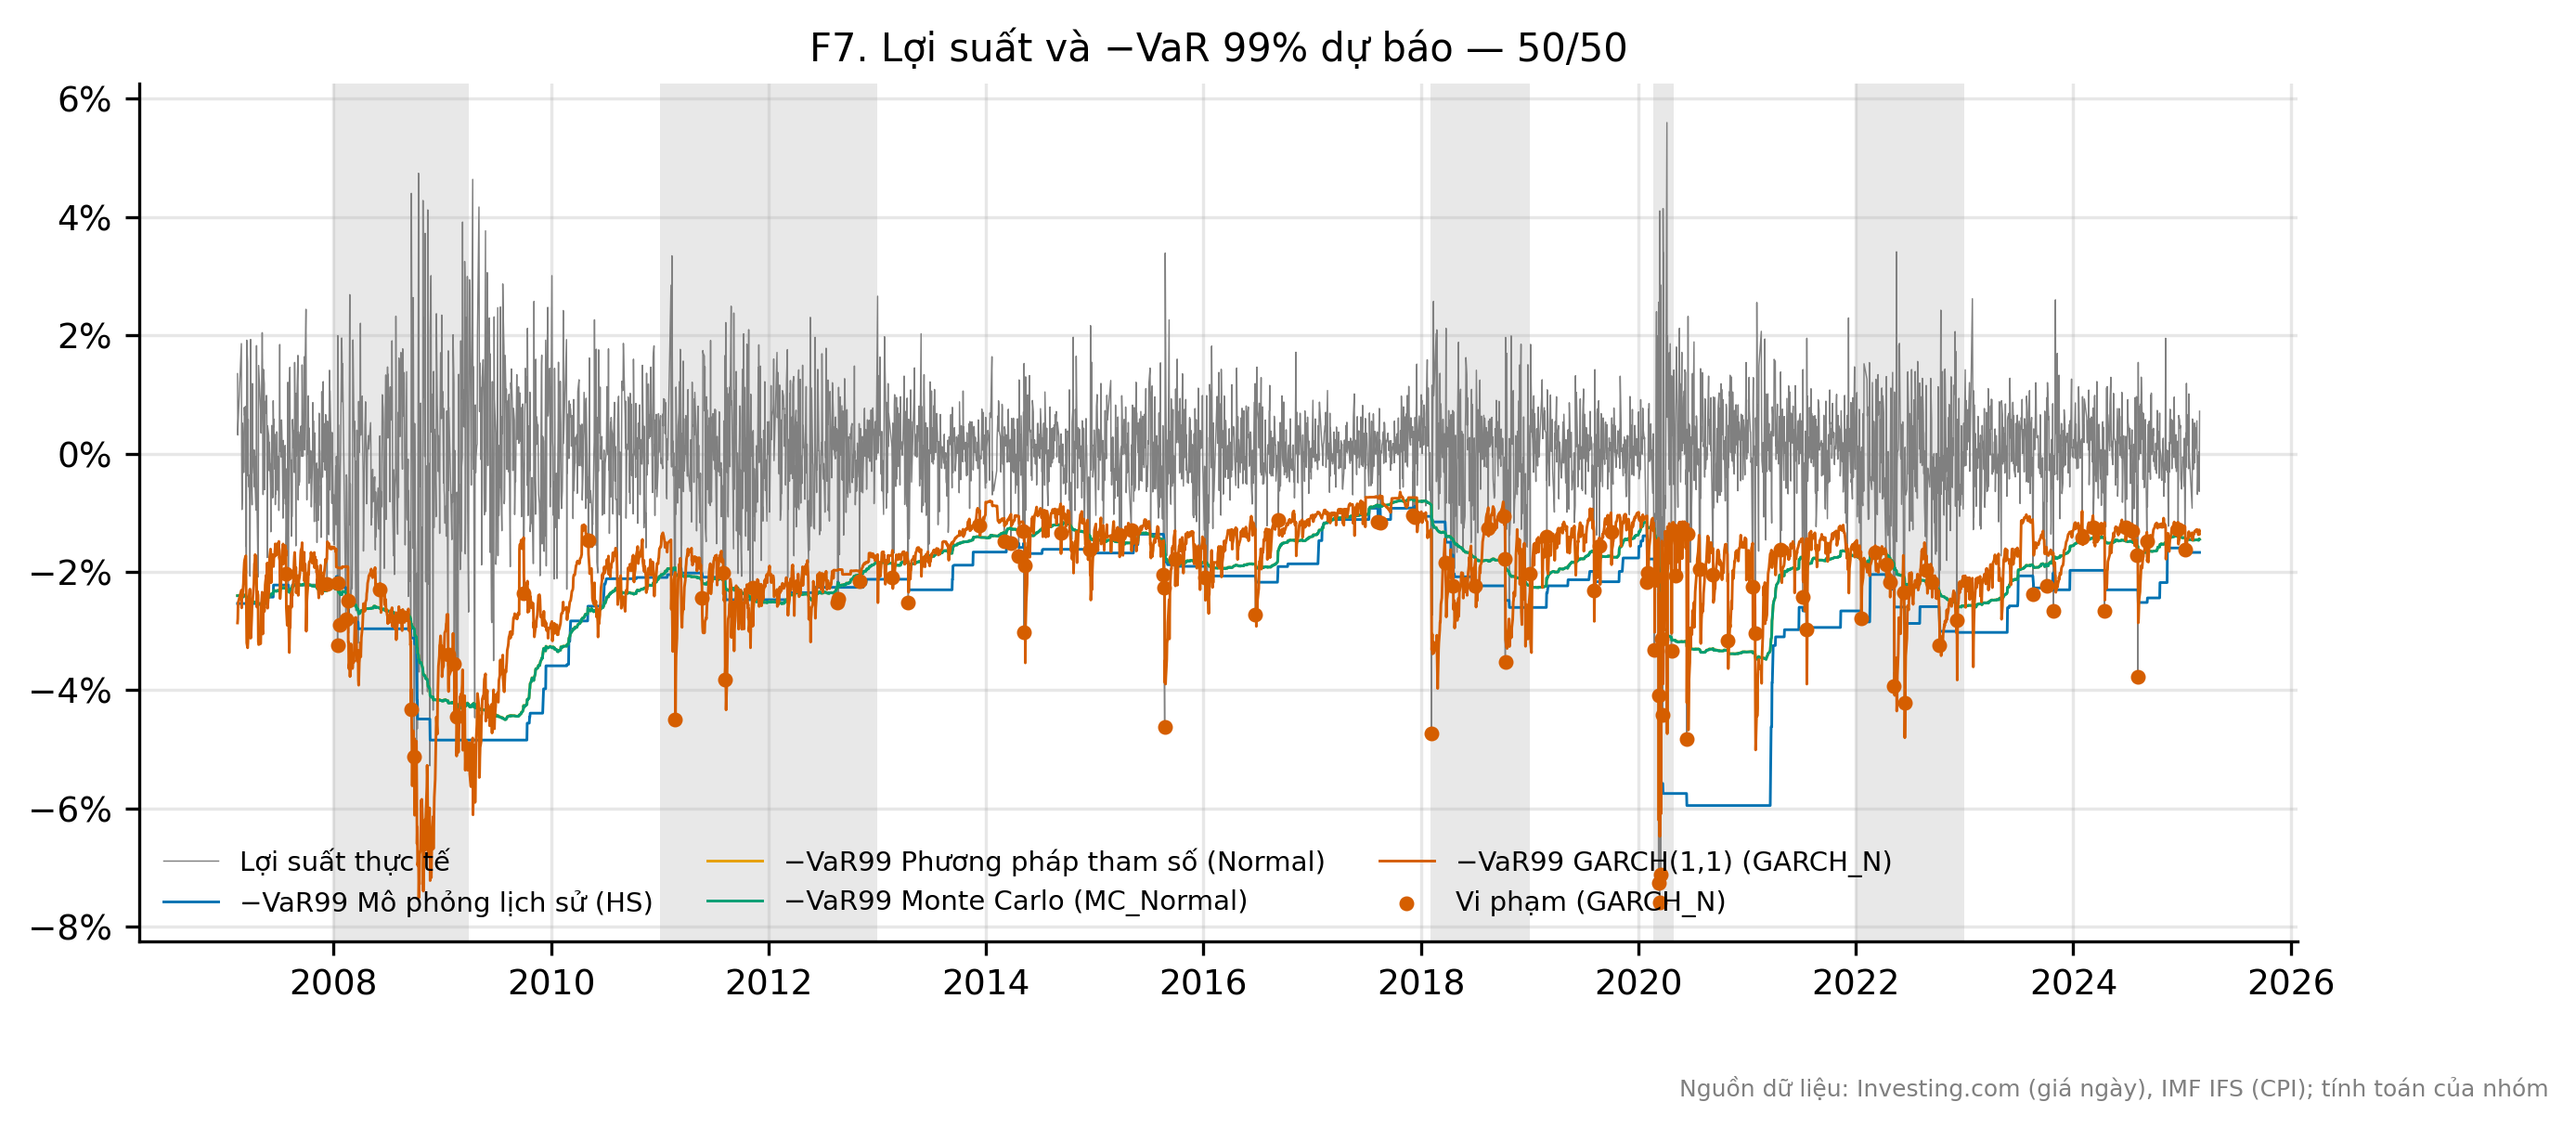

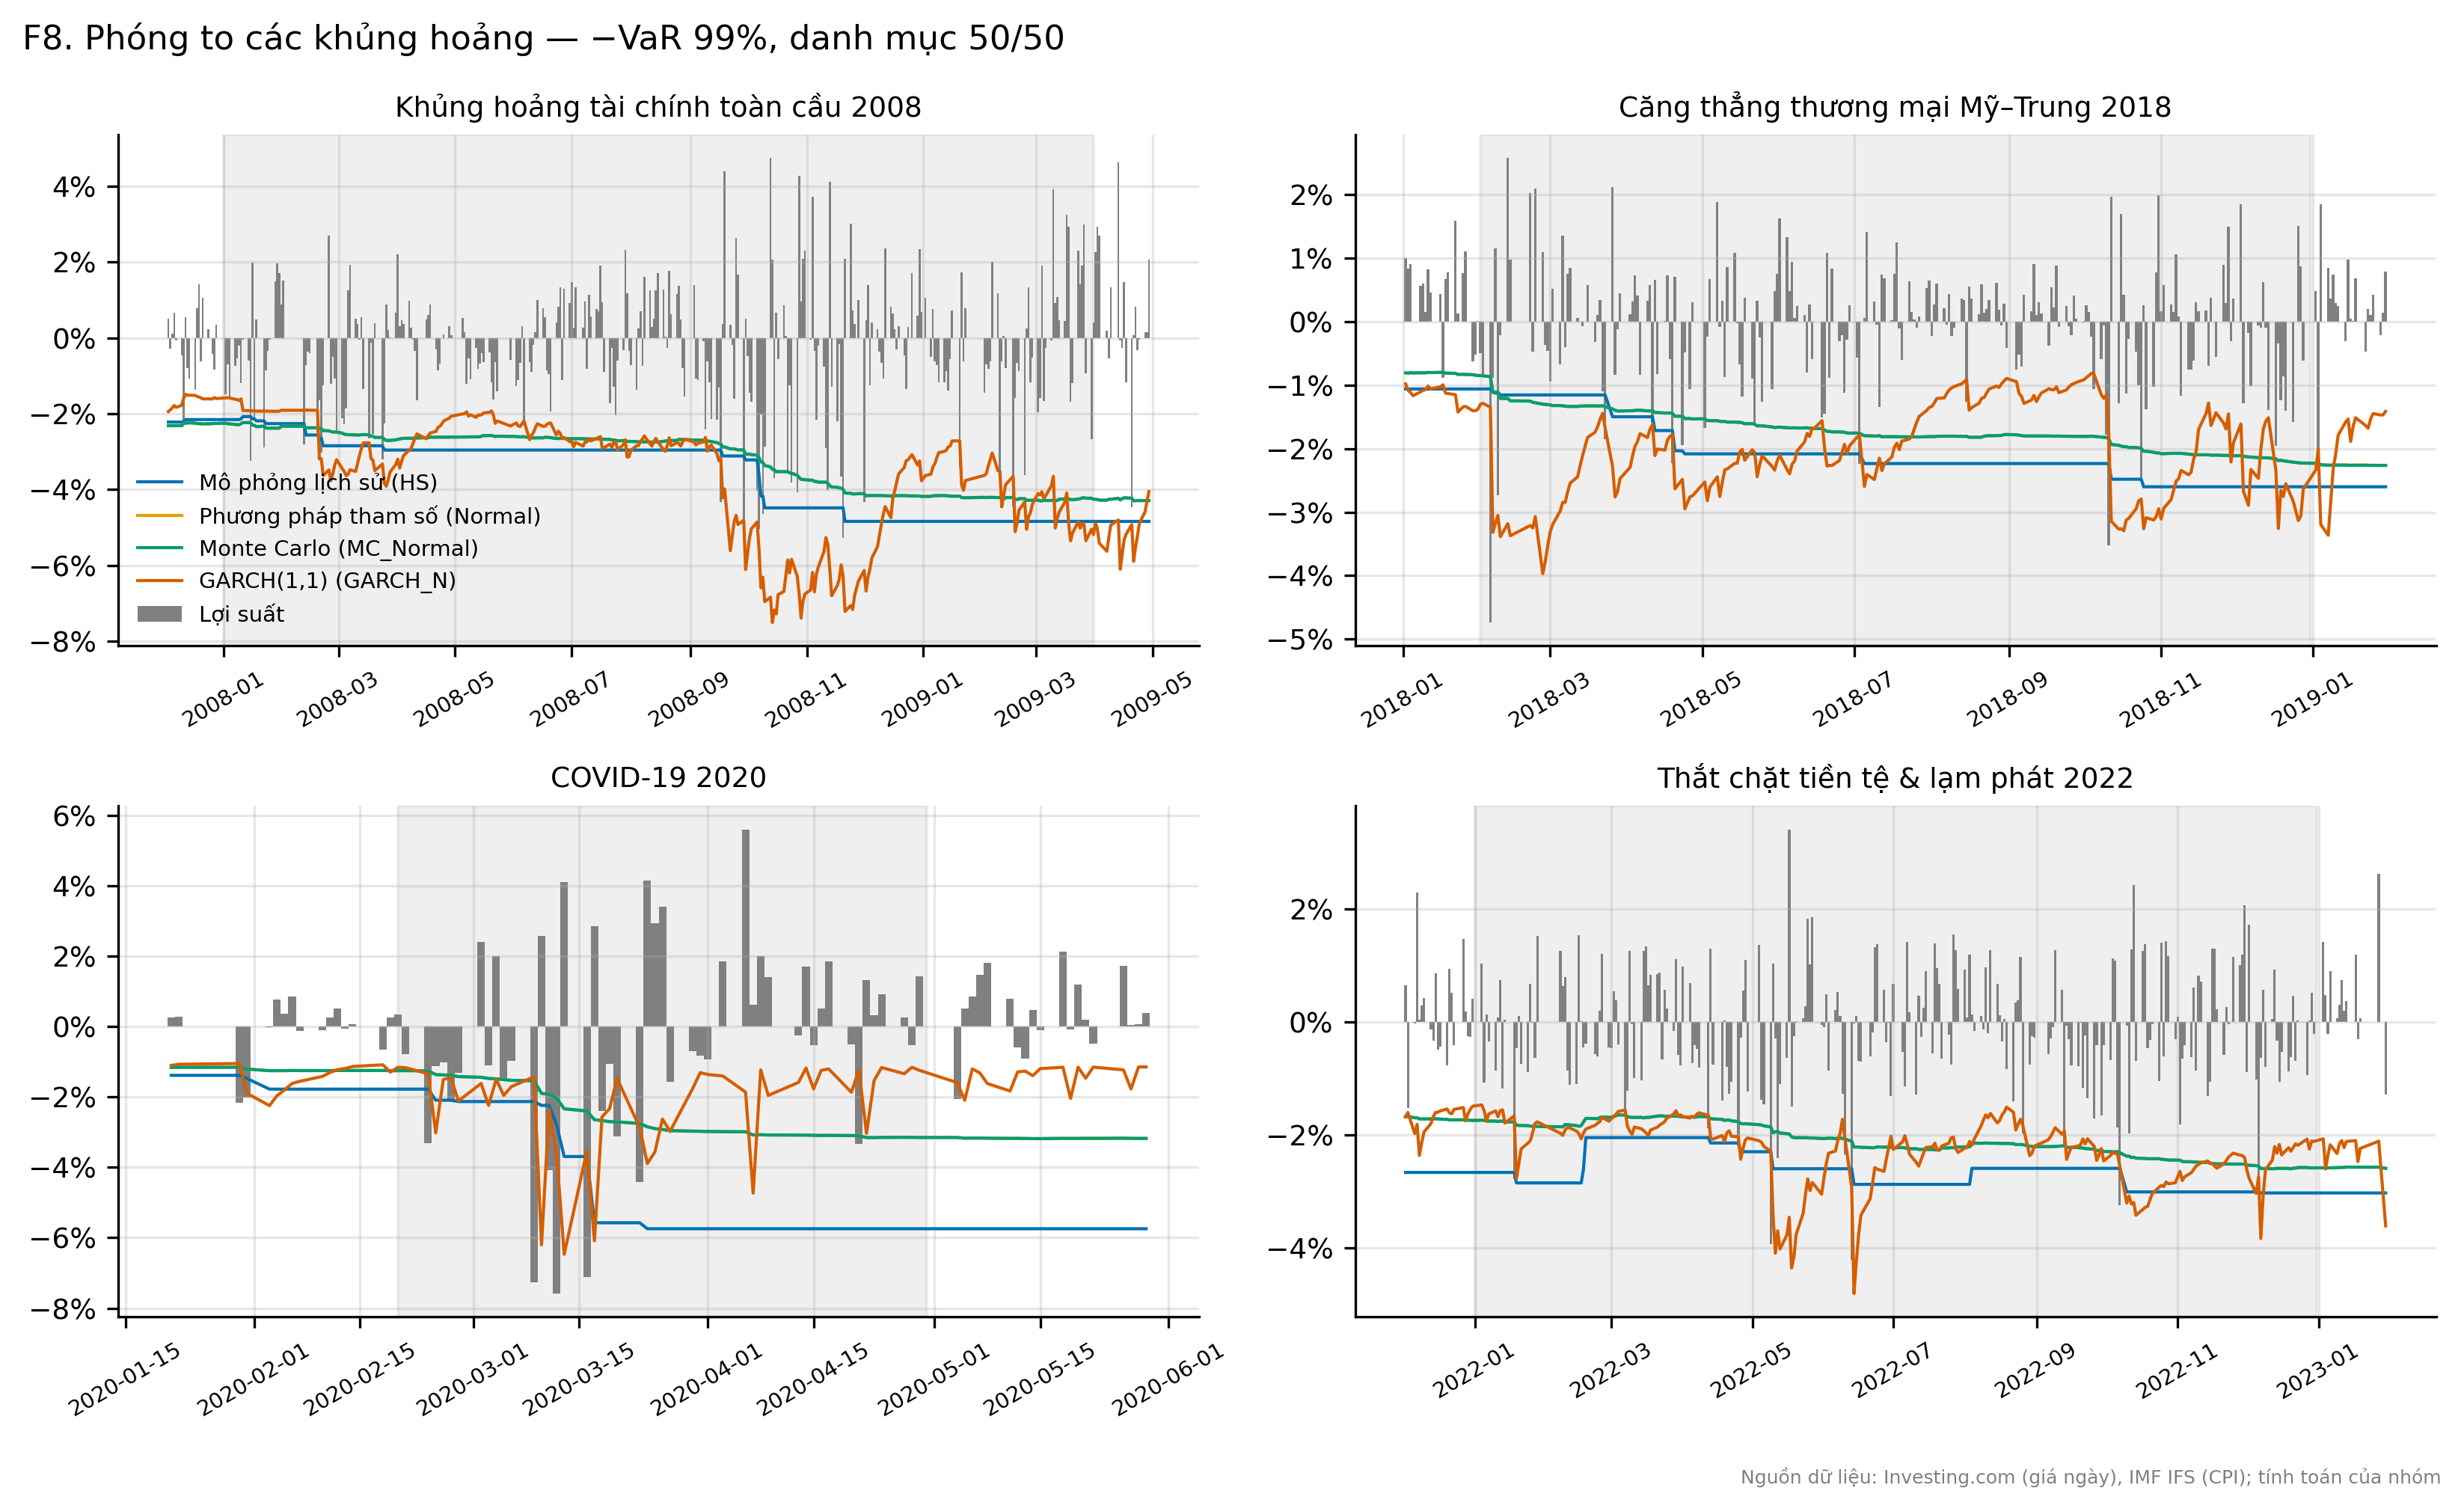

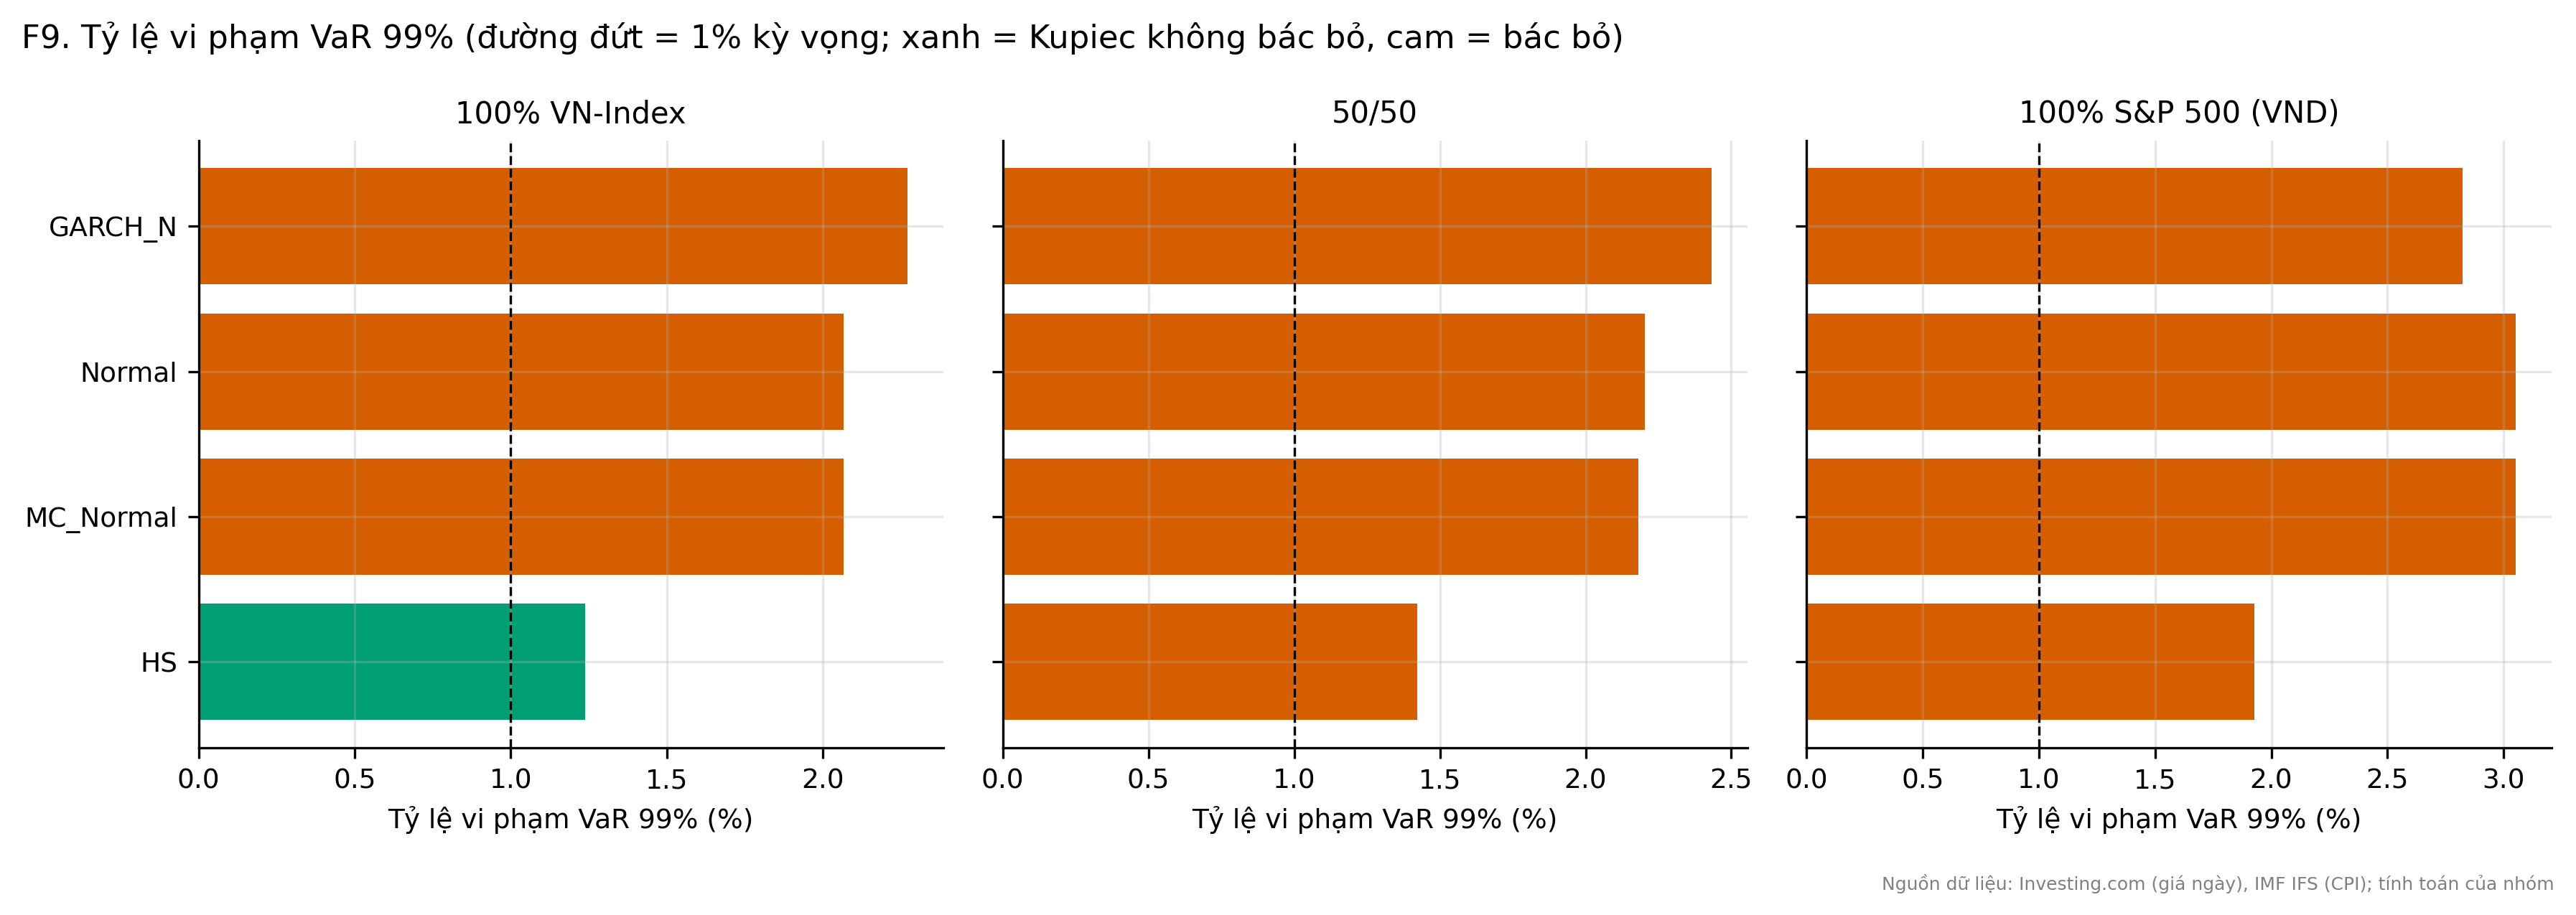

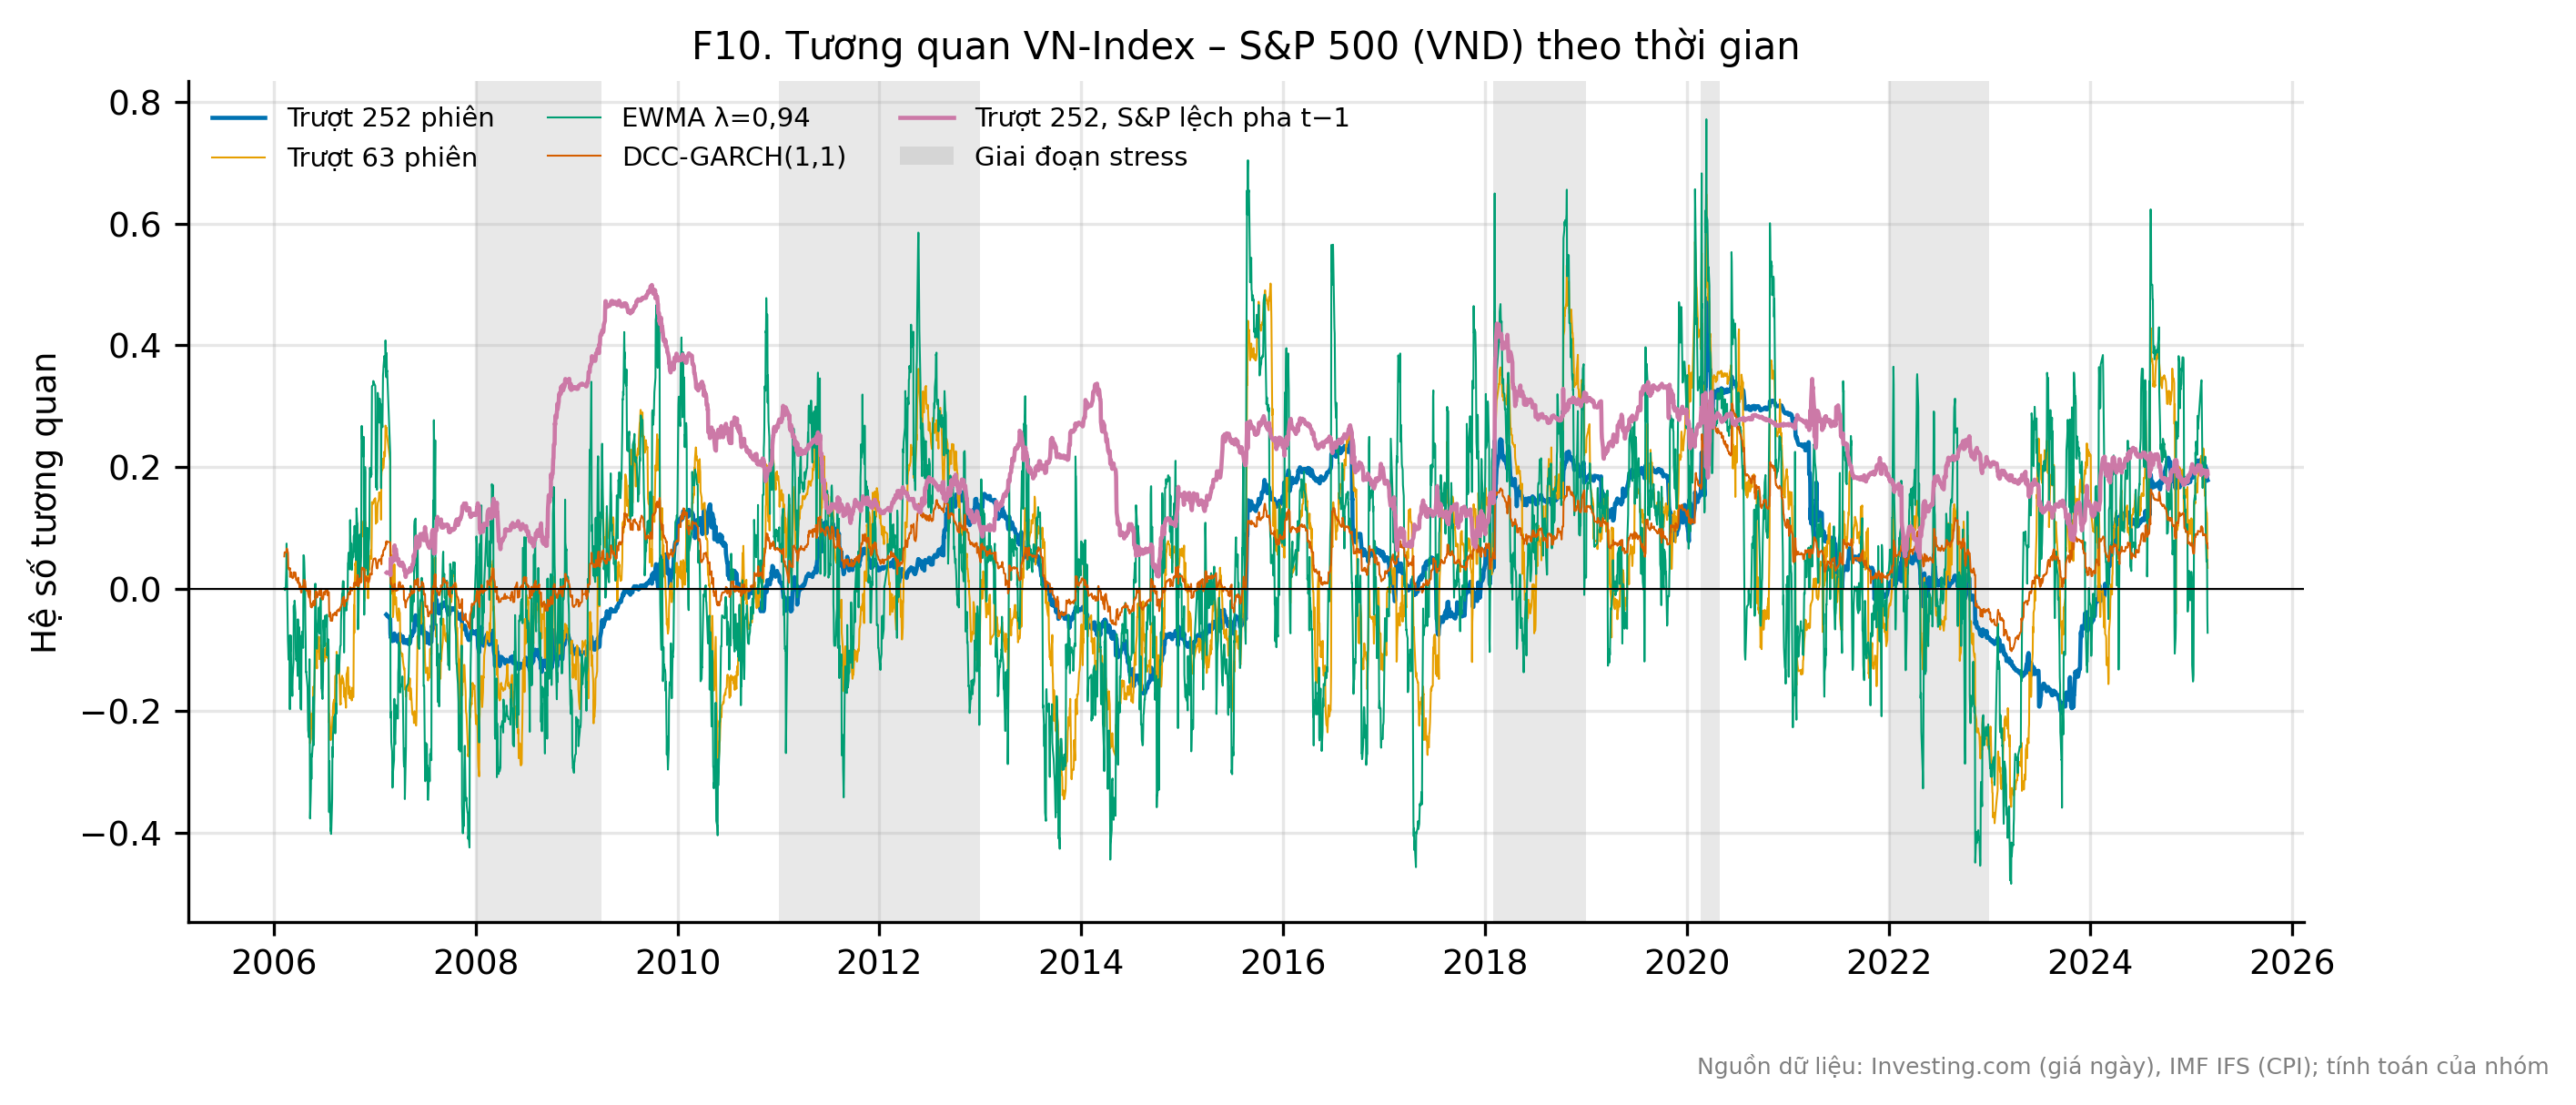

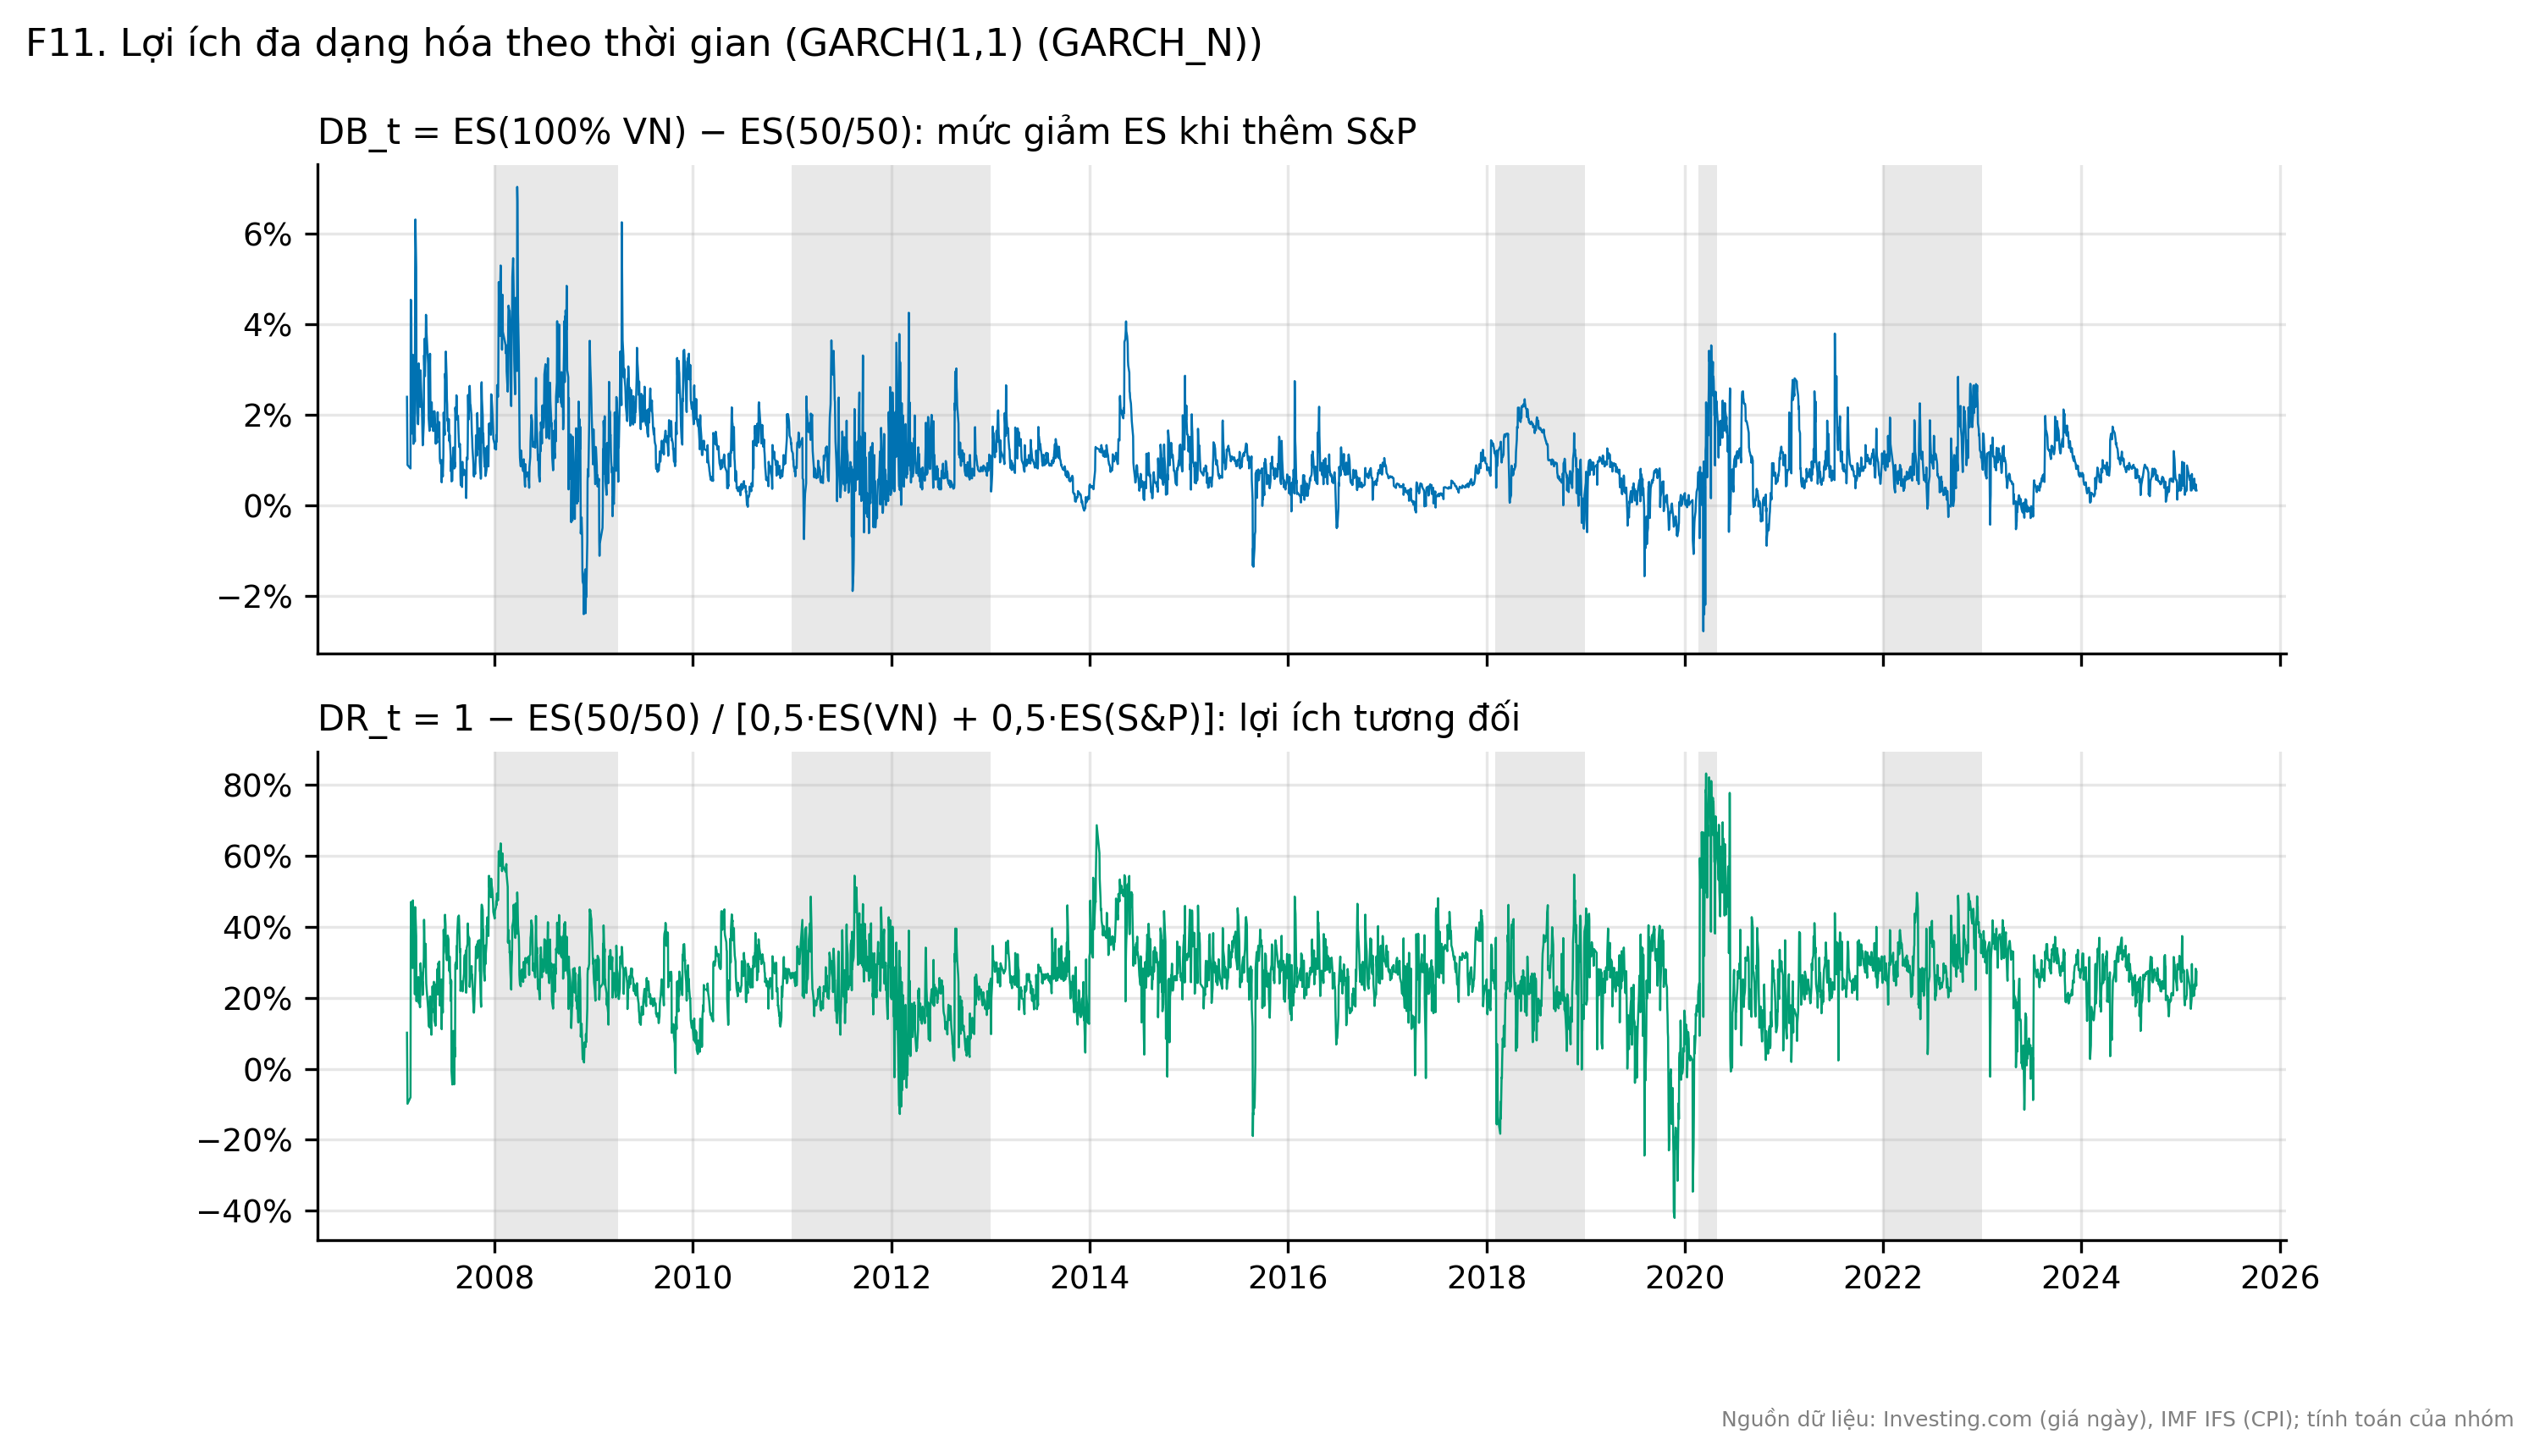

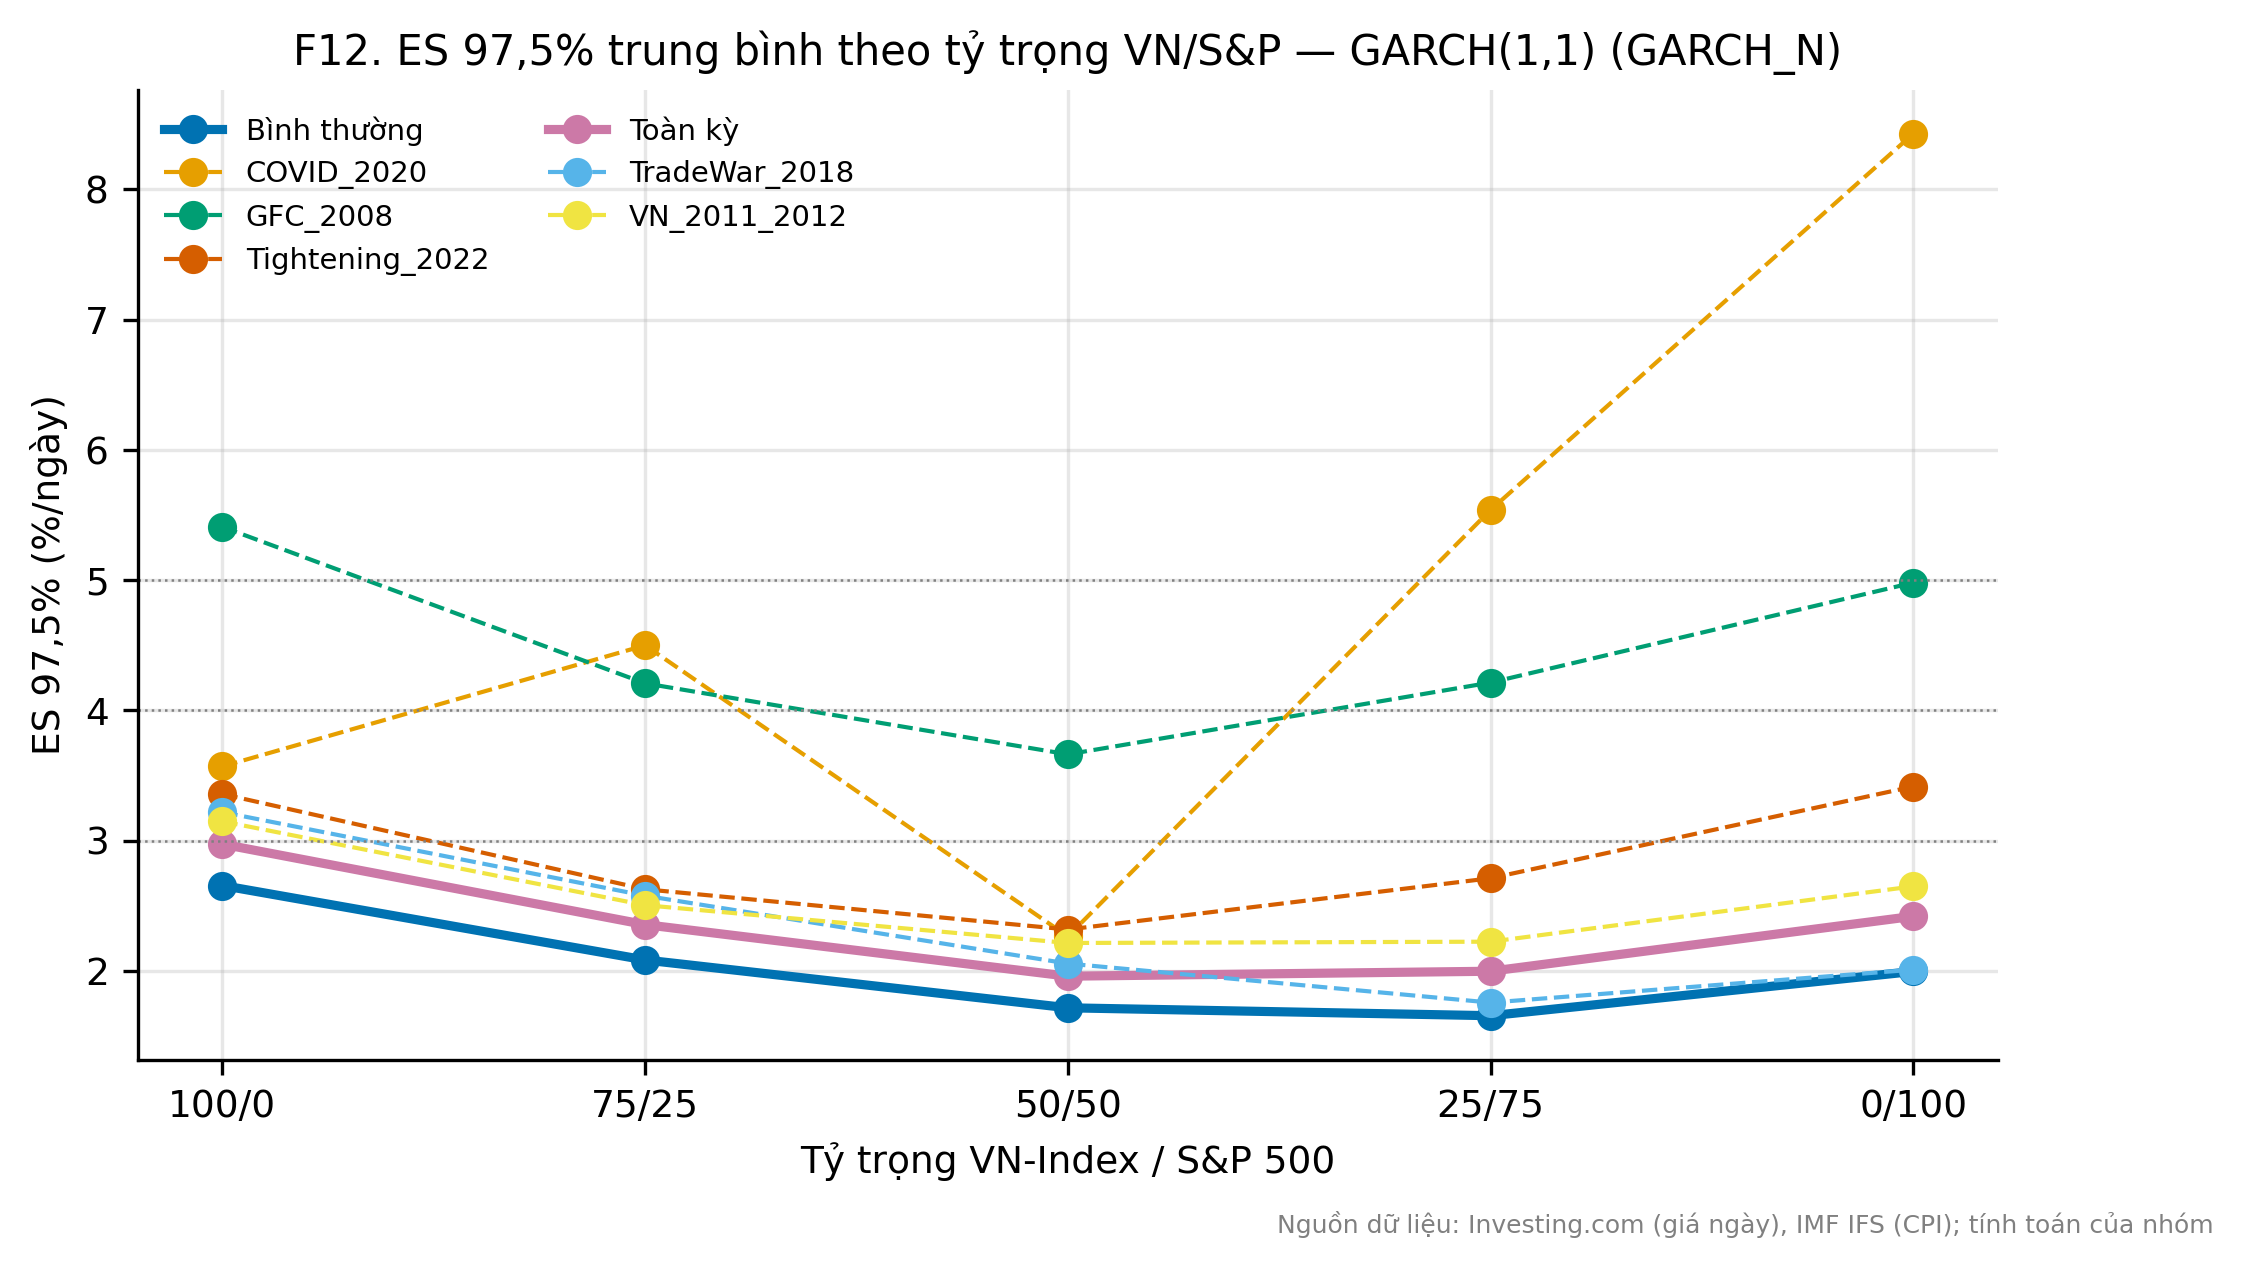

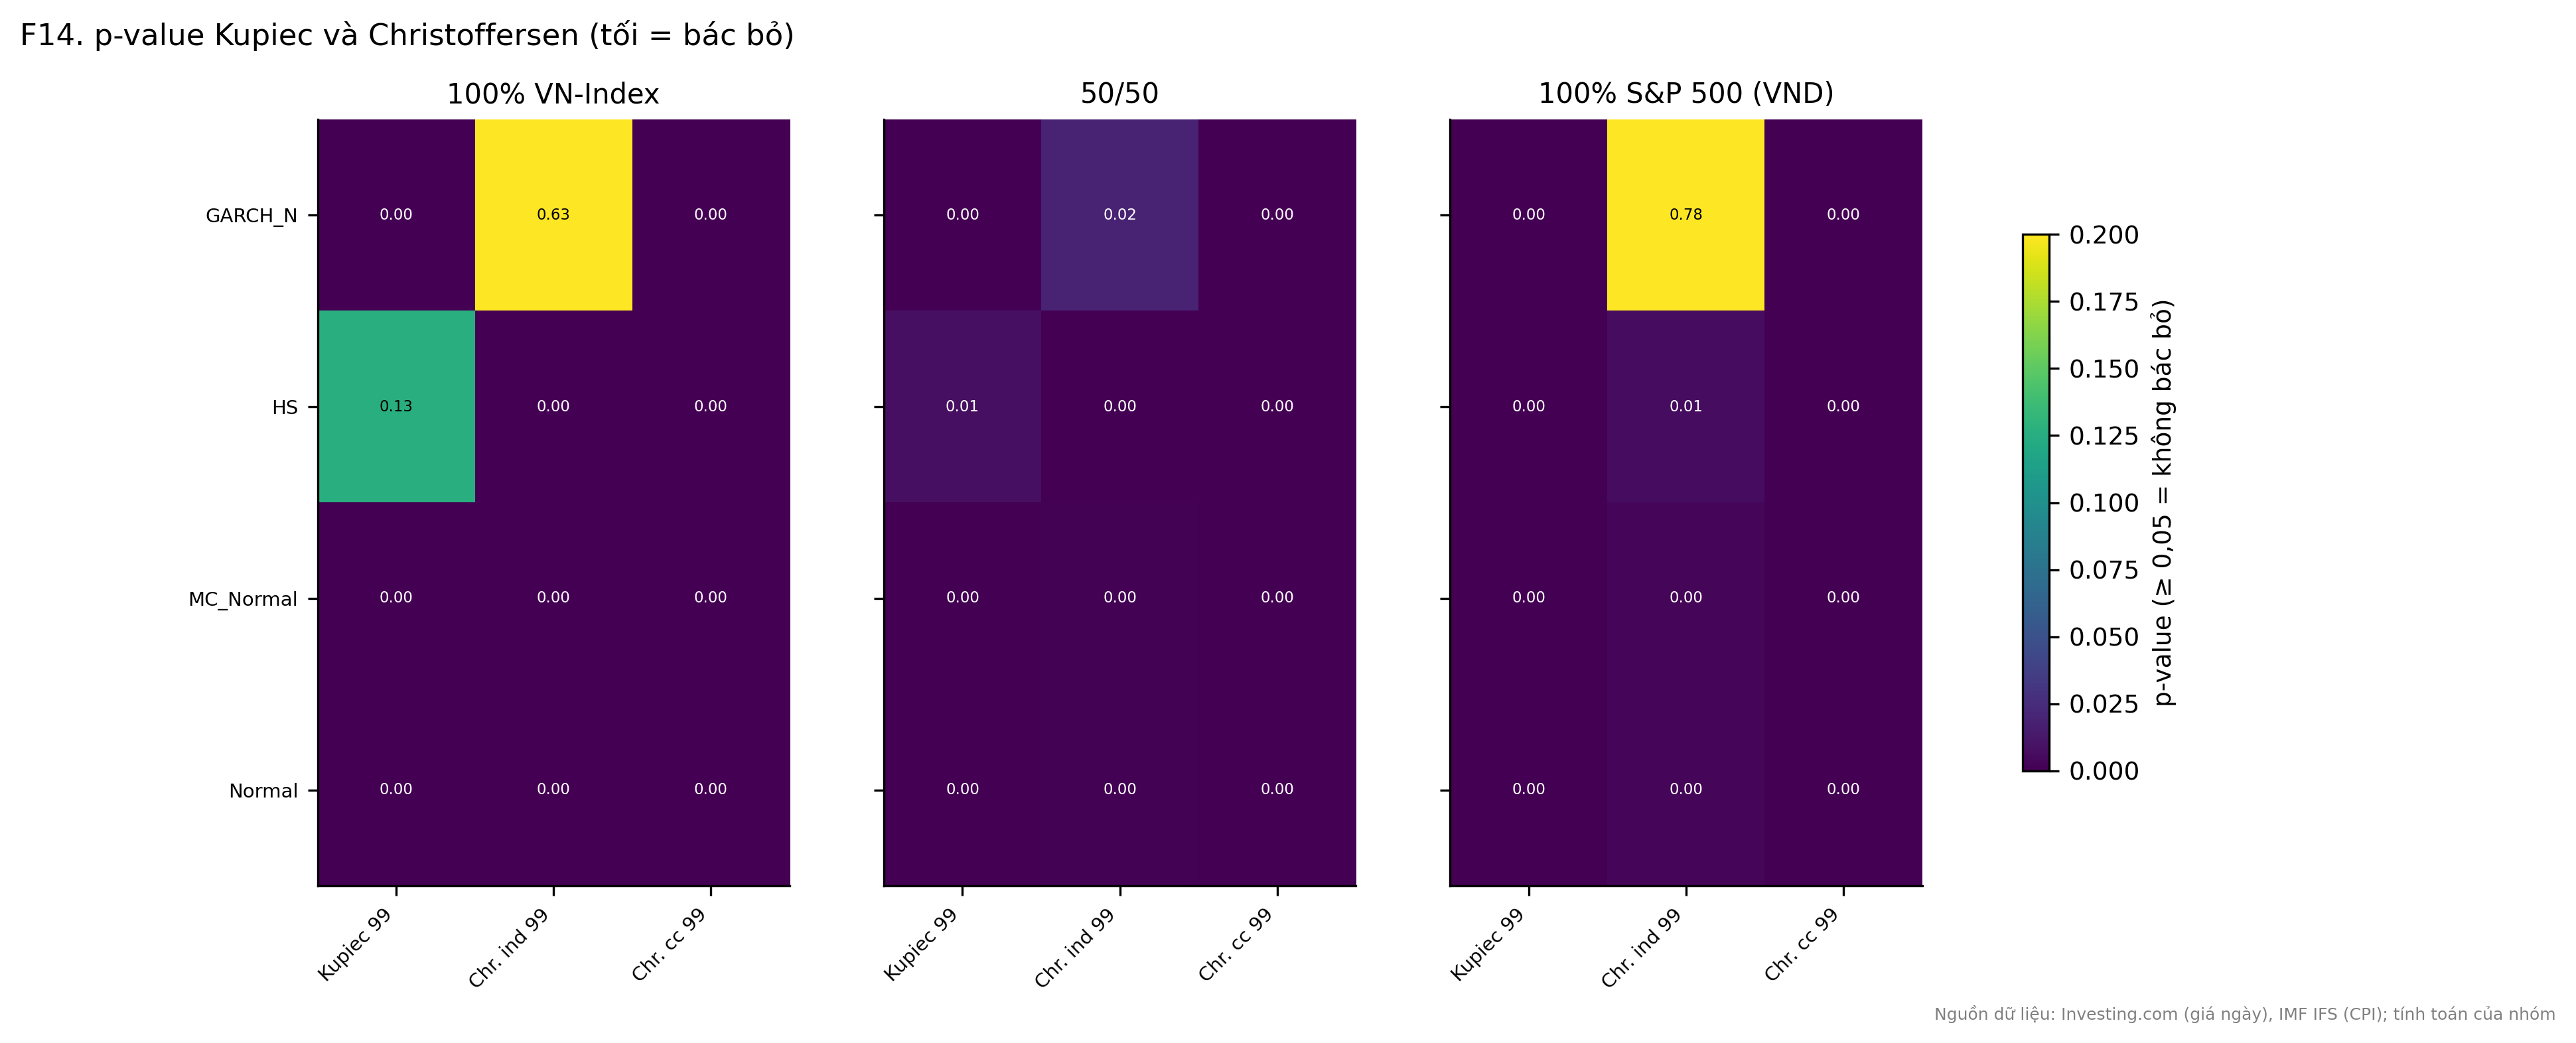

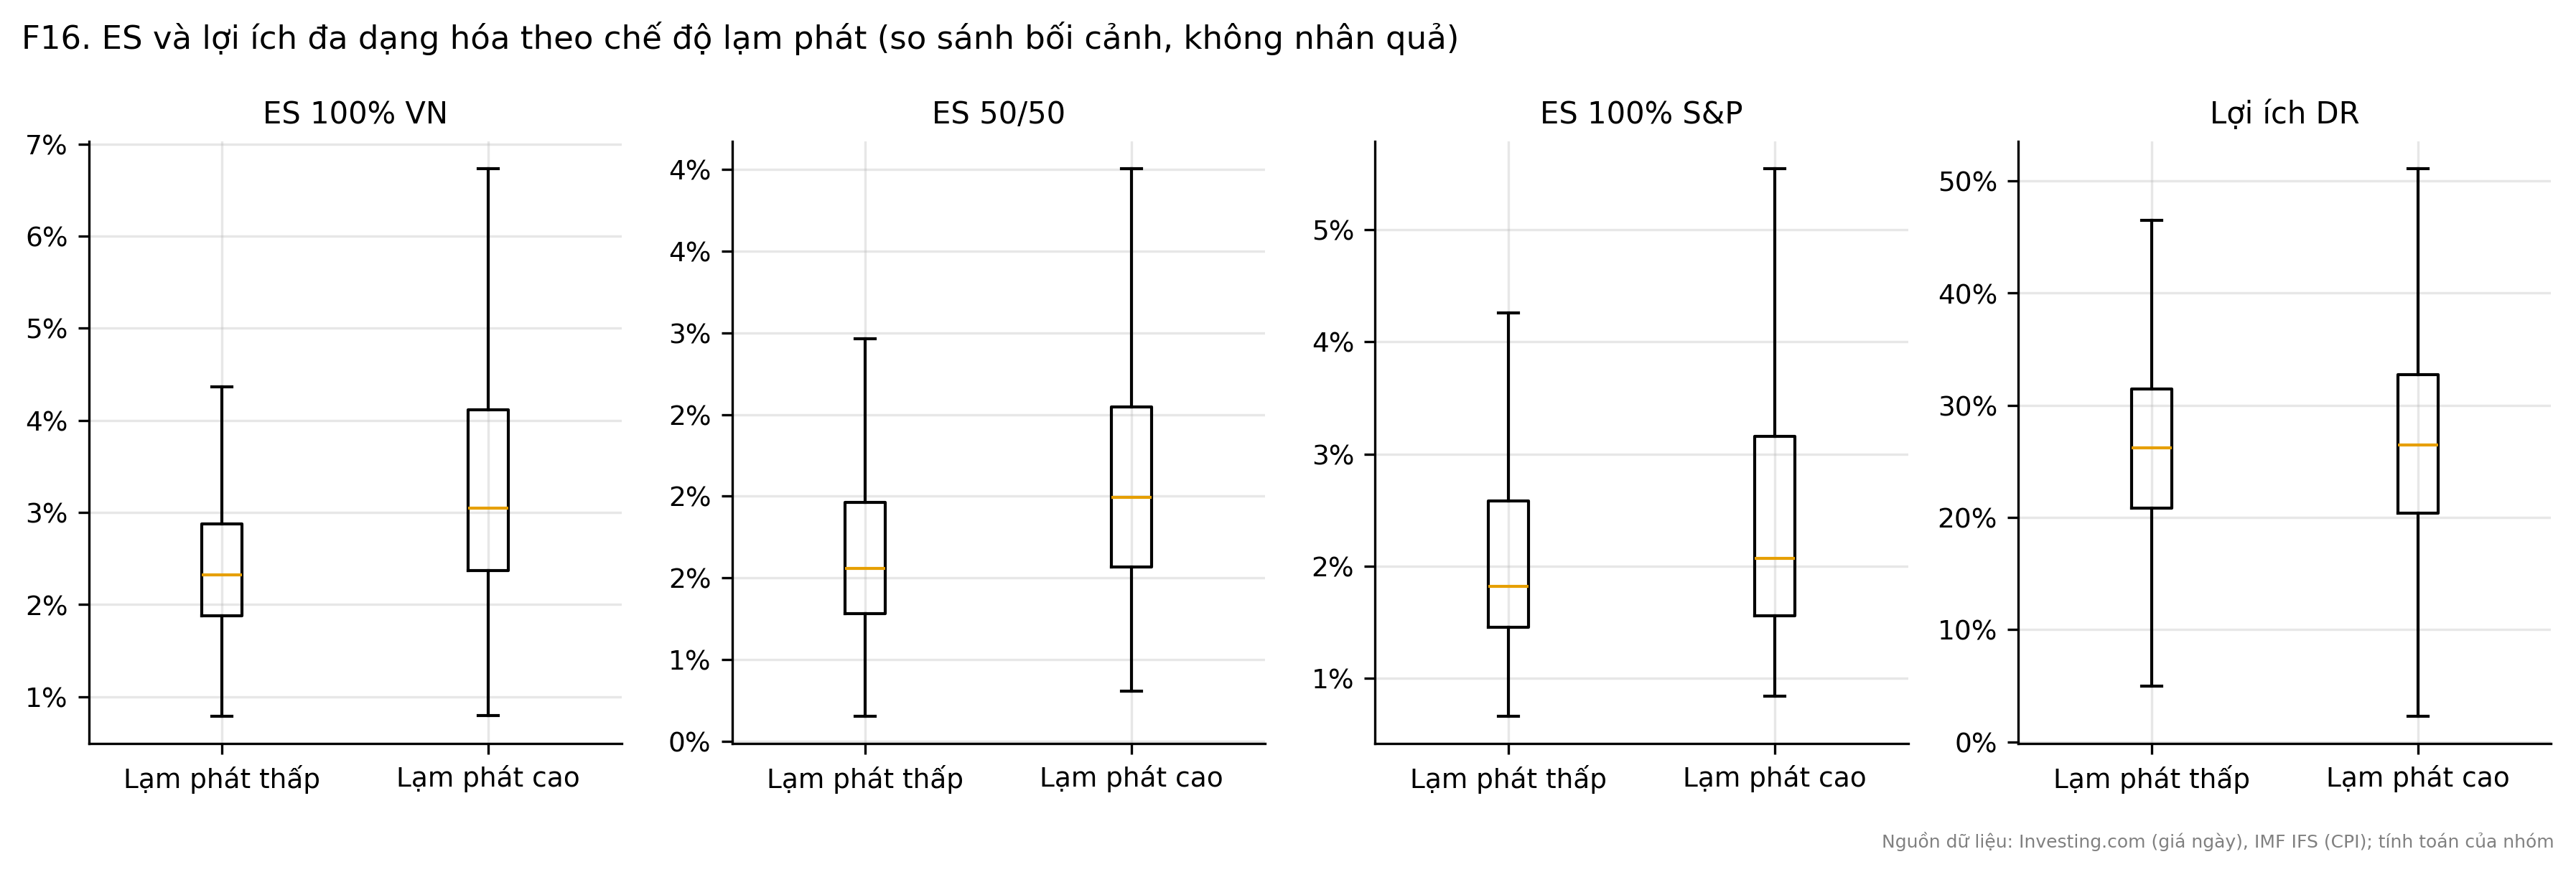

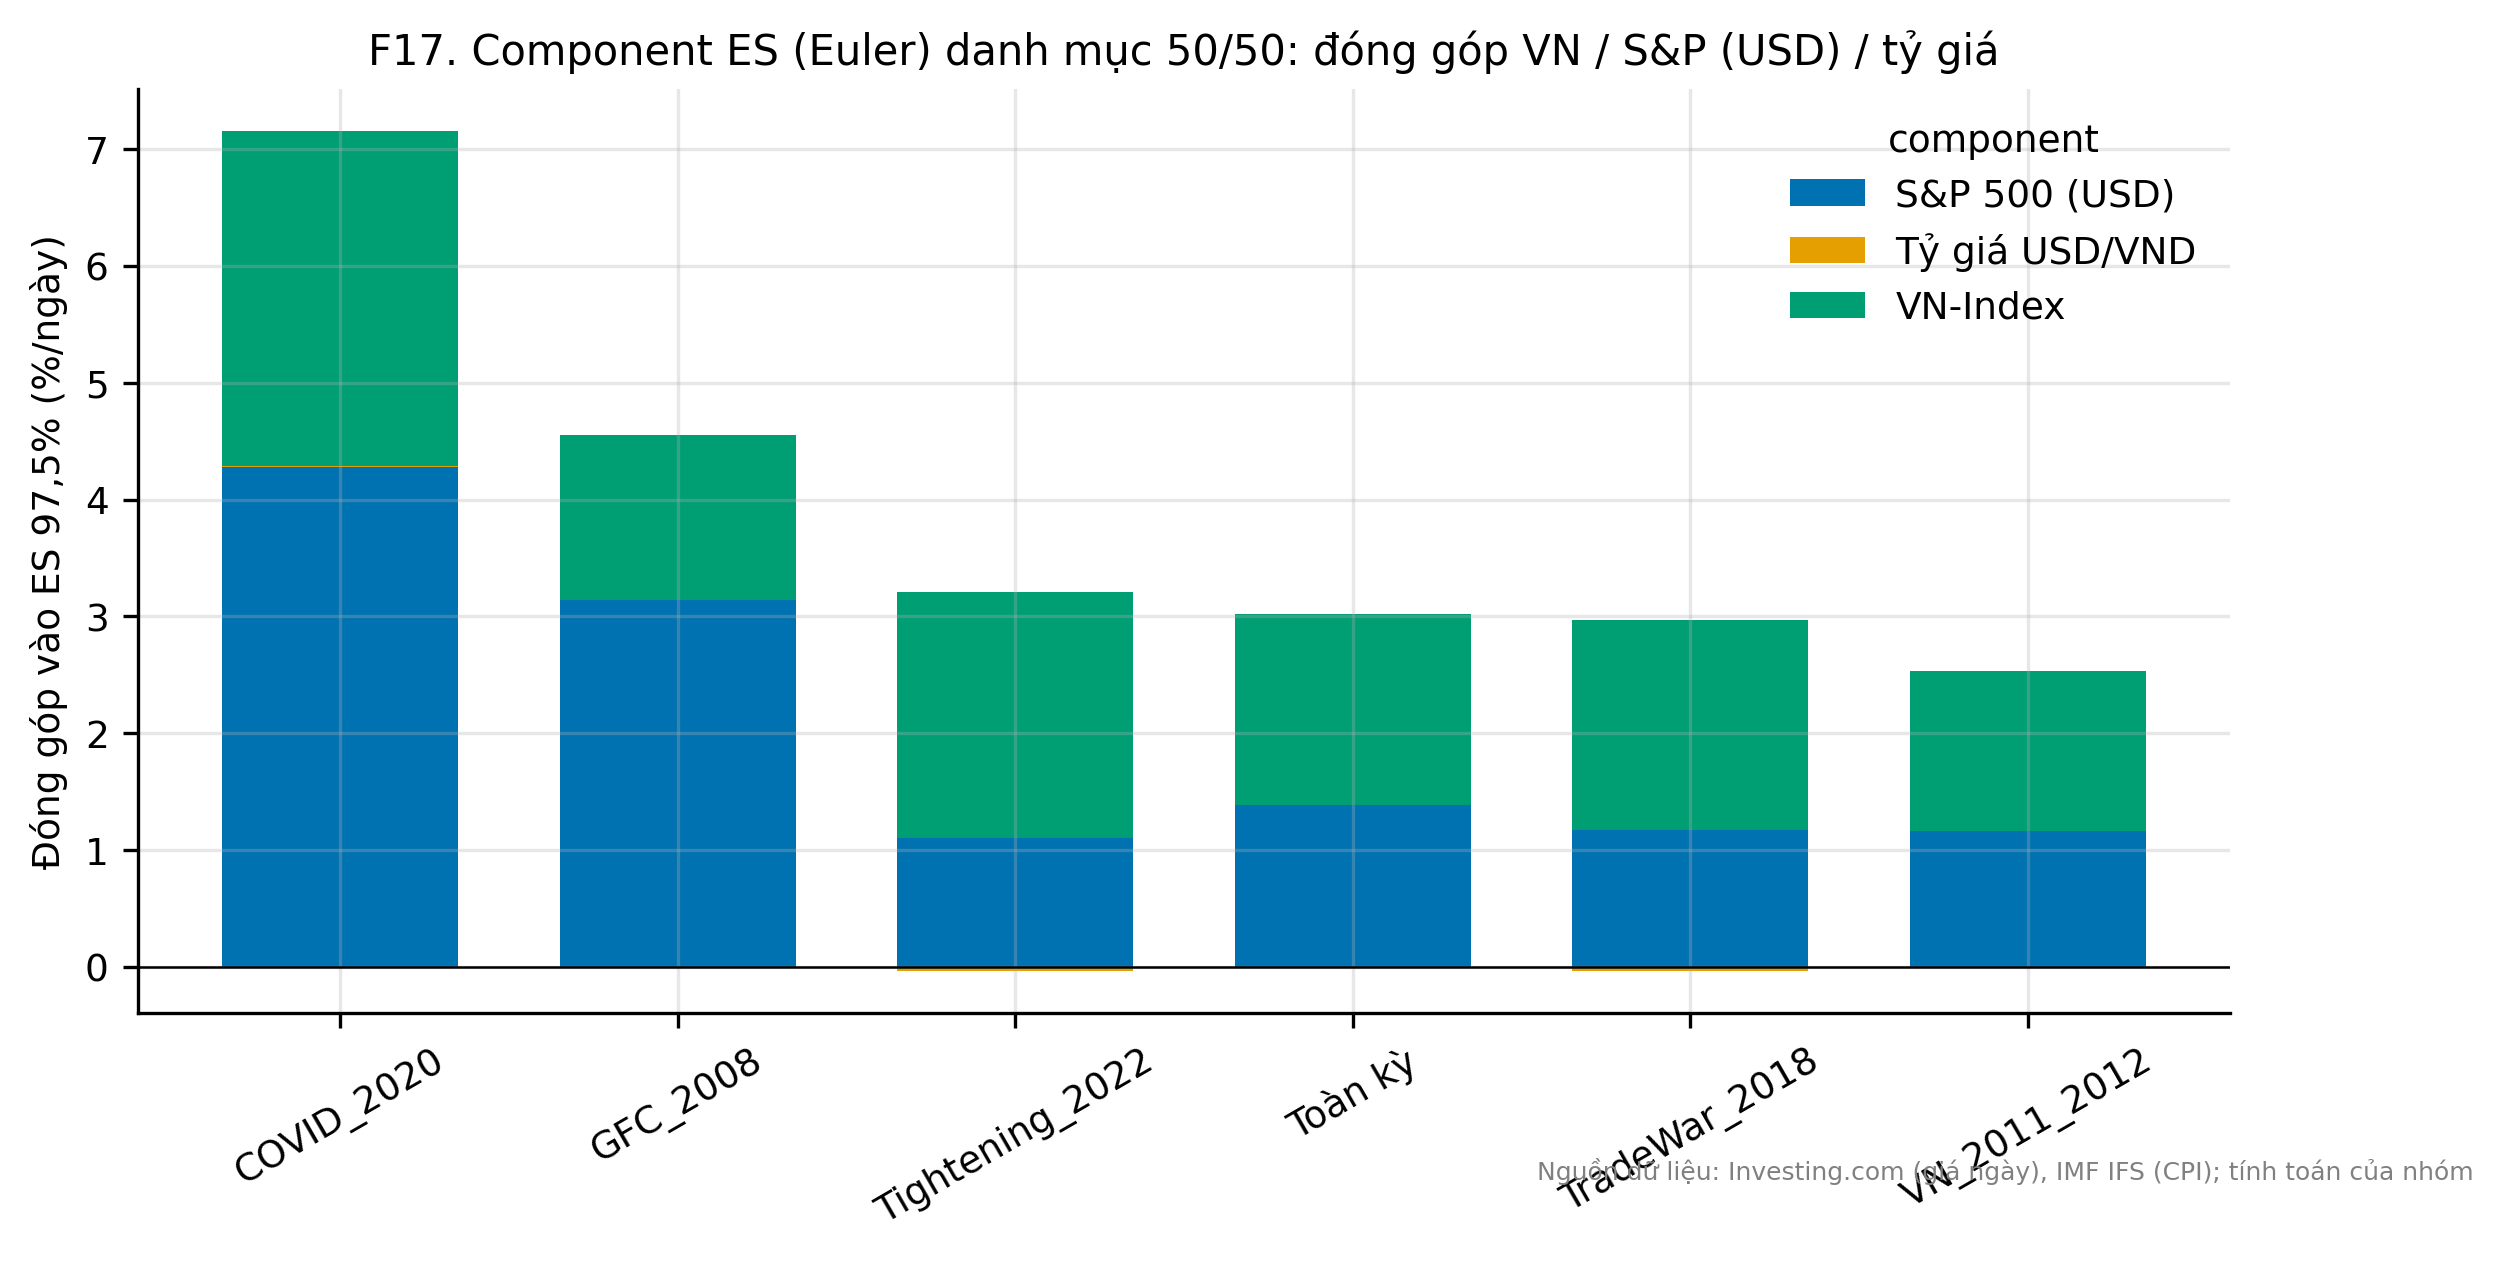

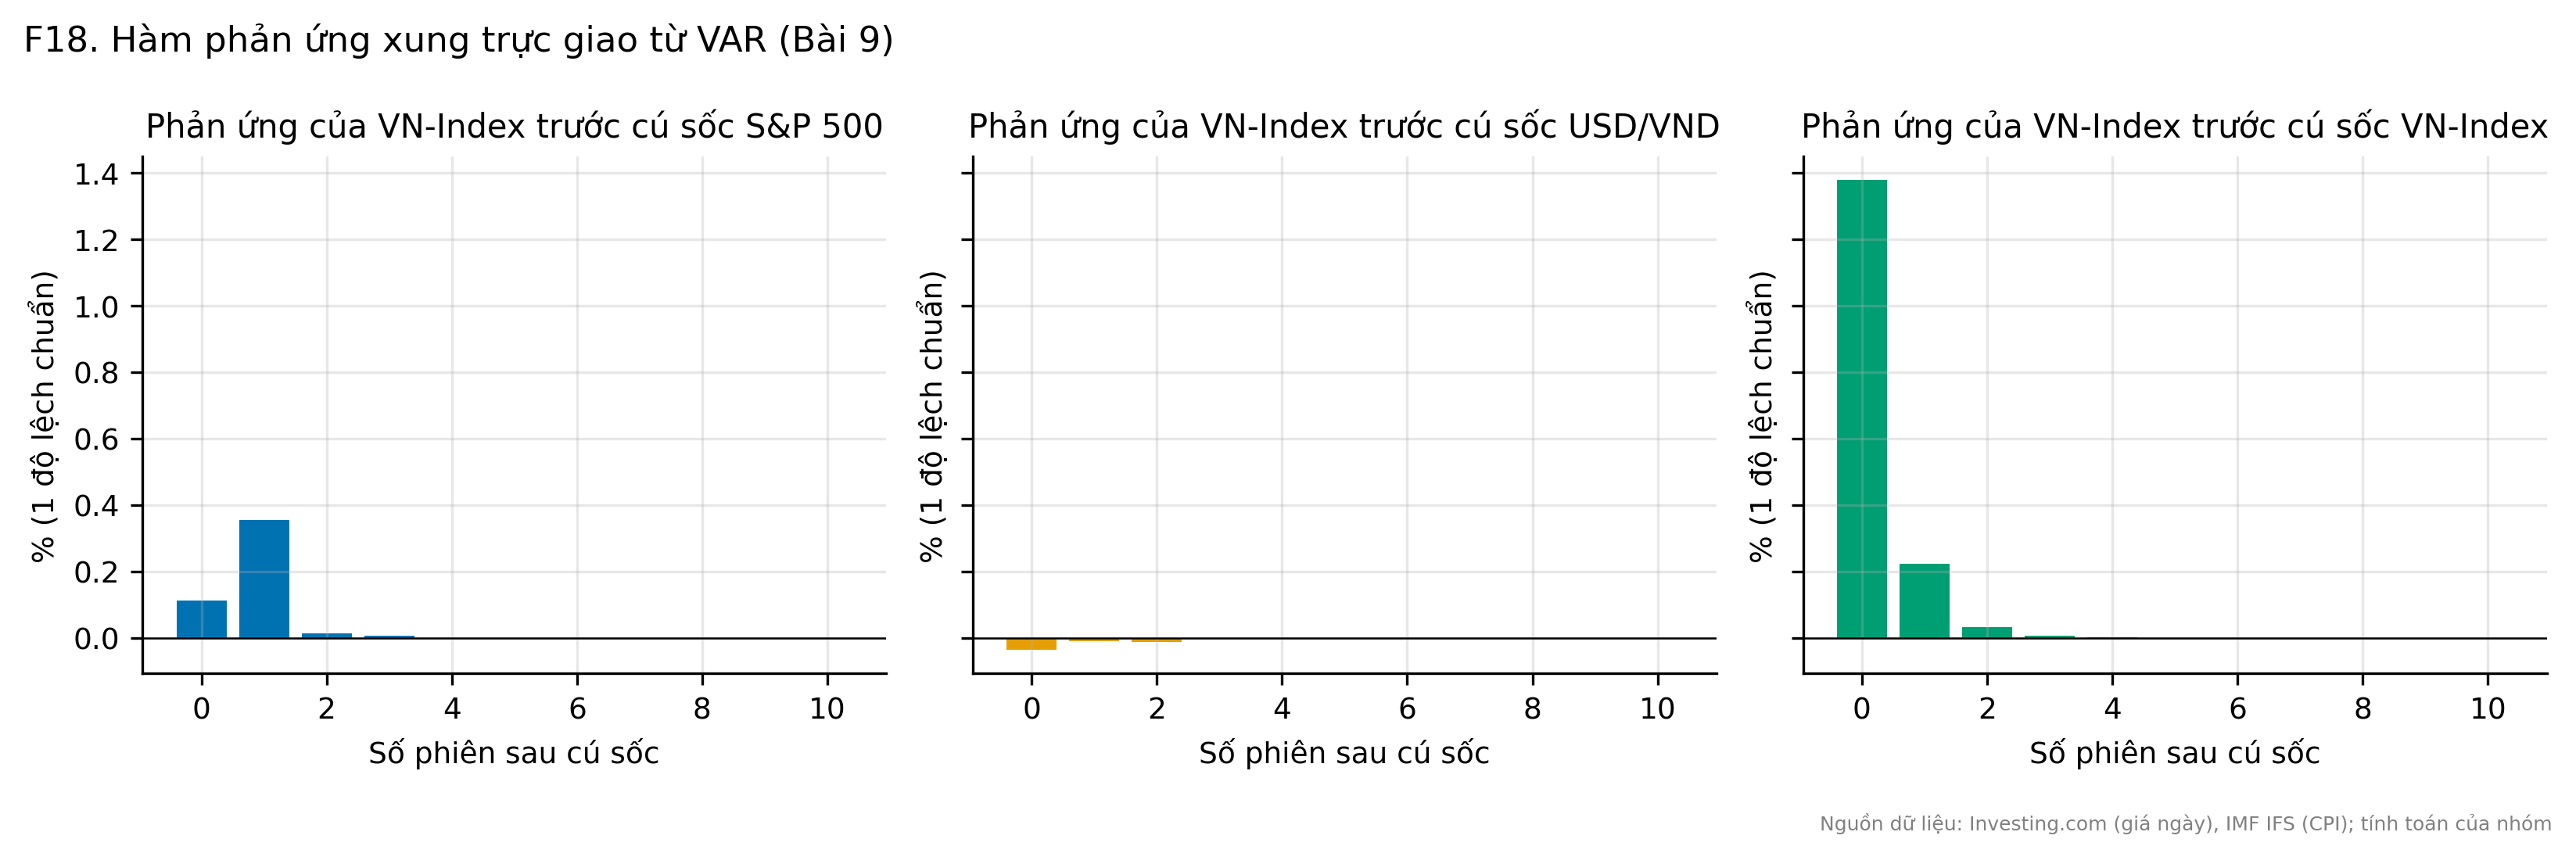

In [12]:
plots.run(cfg); reporting.run(cfg)
for f in ['F7_var_paths_VN50_SP50','F8_crisis_zoom','F9_exceedances','F10_rolling_corr','F11_div_benefit','F12_es_by_weight_GARCH_N','F14_backtest_heatmap','F16_inflation_regime_es','F17_component_es','F18_var_irf']:
    fig(f)

## 9b. Kiểm tra tái lập
So các chỉ tiêu then chốt với bộ tham chiếu của nhóm (`outputs/reproducibility/tham_chieu.json`).

In [13]:
import subprocess
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'verify_reproducibility.py')], capture_output=True, text=True, encoding='utf-8', cwd=ROOT)
print(r.stdout[-700:])

KẾT LUẬN KIỂM TRA TÁI LẬP: KHỚP — cả 100 chỉ tiêu trùng với kết quả của nhóm
Báo cáo chi tiết: C:\Users\X1\AppData\Local\Packages\Claude_pzs8sxrjxfjjc\LocalCache\Roaming\Claude\scratch-workspaces\a61389fd-53fd-443f-8f94-48c006a13016\ca9ca959-b22c-43c3-961f-c192fed66f96\scratch-2026-09-30-f45ee8\v3\DeAn03_VaR_ES_Backtesting\outputs\reproducibility\BAO_CAO_TAI_LAP.html



## 10. Hạn chế
- Tỷ giá lấy từ file giá clean, đã lọc 3 điểm lỗi báo giá (T0_fx_cleaning_log); T9c so sánh toàn mẫu với mẫu con từ 2014.
- Lệch múi giờ VN–Mỹ: phiên Mỹ đóng cửa sau phiên VN; robustness với dữ liệu lệch pha.
- Lạm phát chỉ để chia bối cảnh, không kết luận nhân quả; chuỗi CPI lấy từ file clean thứ hai.
- Chỉ số không phải tài sản đầu tư trực tiếp; bỏ qua phí, thuế, hạn chế chuyển vốn.